In [3]:
import scanpy as sc
import anndata as ad
import scanpy.external as sce
import spatialdata as sd
import squidpy as sq
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from tqdm.auto import tqdm
import os
import sys
from SpatialQuery import spatial_query_multi

from skimage.color import rgb2lab, lab2rgb
from matplotlib.colors import to_rgb, to_hex

/home/nig060/miniconda3/envs/python3.10/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/nig060/miniconda3/envs/python3.10/lib/python3.10/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
/home/nig060/miniconda3/envs/python3.10/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, Fut

In [3]:
xen = sc.read_h5ad('../Graham_Chemo_Cell_Types_v3.h5ad')

In [34]:
celltype_rctd_filtered = pd.crosstab(xen.obs['cell_type'], xen.obs['RCTD_first_filtered'])
celltype_rctd_filtered

RCTD_first_filtered,B Cells,CAFs,Cycling Epi Cancer,Cycling Macrophages,Cycling Mes Cancer,DCs,Endothelial,Epi Cancer,M1 Macrophages,M2 Macrophages,Mes Cancer,Neutrophils,Pericytes,Plasma Cells,T cells,Tissue Resident Macrophages
cell_type,,,,,,,,,,,,,,,,
B cells,23367,136,1,3,3,49,1,0,18,14,30,1,12,142,91,32
DCs,152,55,3,35,89,1459,88,5,207,163,96,2,17,49,31,48
Endothelial cells,412,91,1,98,710,28,5762,5,478,105,186,45,2000,139,34,143
Epi Cancer,81,28,6160,21,167,521,88,15374,205,785,280,342,115,112,35,98
Lymphatic endothelial cells,6,8,0,10,4,0,2,0,10,54,9,1,2,29,0,34
Macrophages,120,39,32,6820,7582,305,109,23,13382,9410,735,702,148,389,107,5498
Mes Cancer,12,32,7,2308,29329,143,192,3,6626,863,5497,176,92,35,191,1718
Plasma cells,65,136,1,21,3,5,3,0,13,8,25,12,4,4017,0,91
Stroma,151,4185,10,151,154,108,76,16,827,7373,598,255,228,504,39,1627


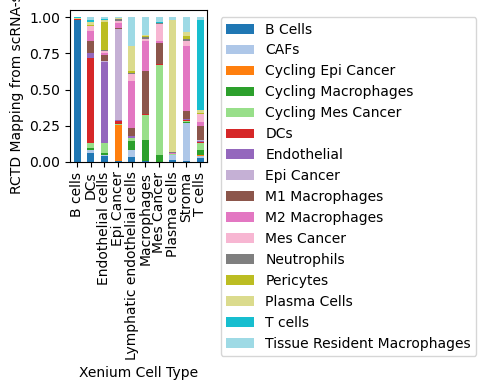

In [35]:
# Normalize and plot 
prop_table = celltype_rctd_filtered.div(celltype_rctd_filtered.sum(axis=1),axis=0)

prop_table.plot(
    kind="bar",
    stacked=True,
    figsize=(5, 4), 
    colormap='tab20'
)

plt.xlabel("Xenium Cell Type")
plt.ylabel("RCTD Mapping from scRNA-seq")
plt.legend(title="Cell Type RCTD Filtered")
plt.xticks(rotation=90)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.savefig("../Plots/102826_Cell_type_RCTD_2.png", dpi=600, bbox_inches="tight")
plt.tight_layout()
plt.show()

/tmp/ipykernel_1529131/3122007228.py:17: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/tmp/ipykernel_1529131/3122007228.py:17: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/tmp/ipykernel_1529131/3122007228.py:17: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/tmp/ipykernel_1529131/3122007228.py:17: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/tmp/ipykernel_1529131/3122007228.py:17: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


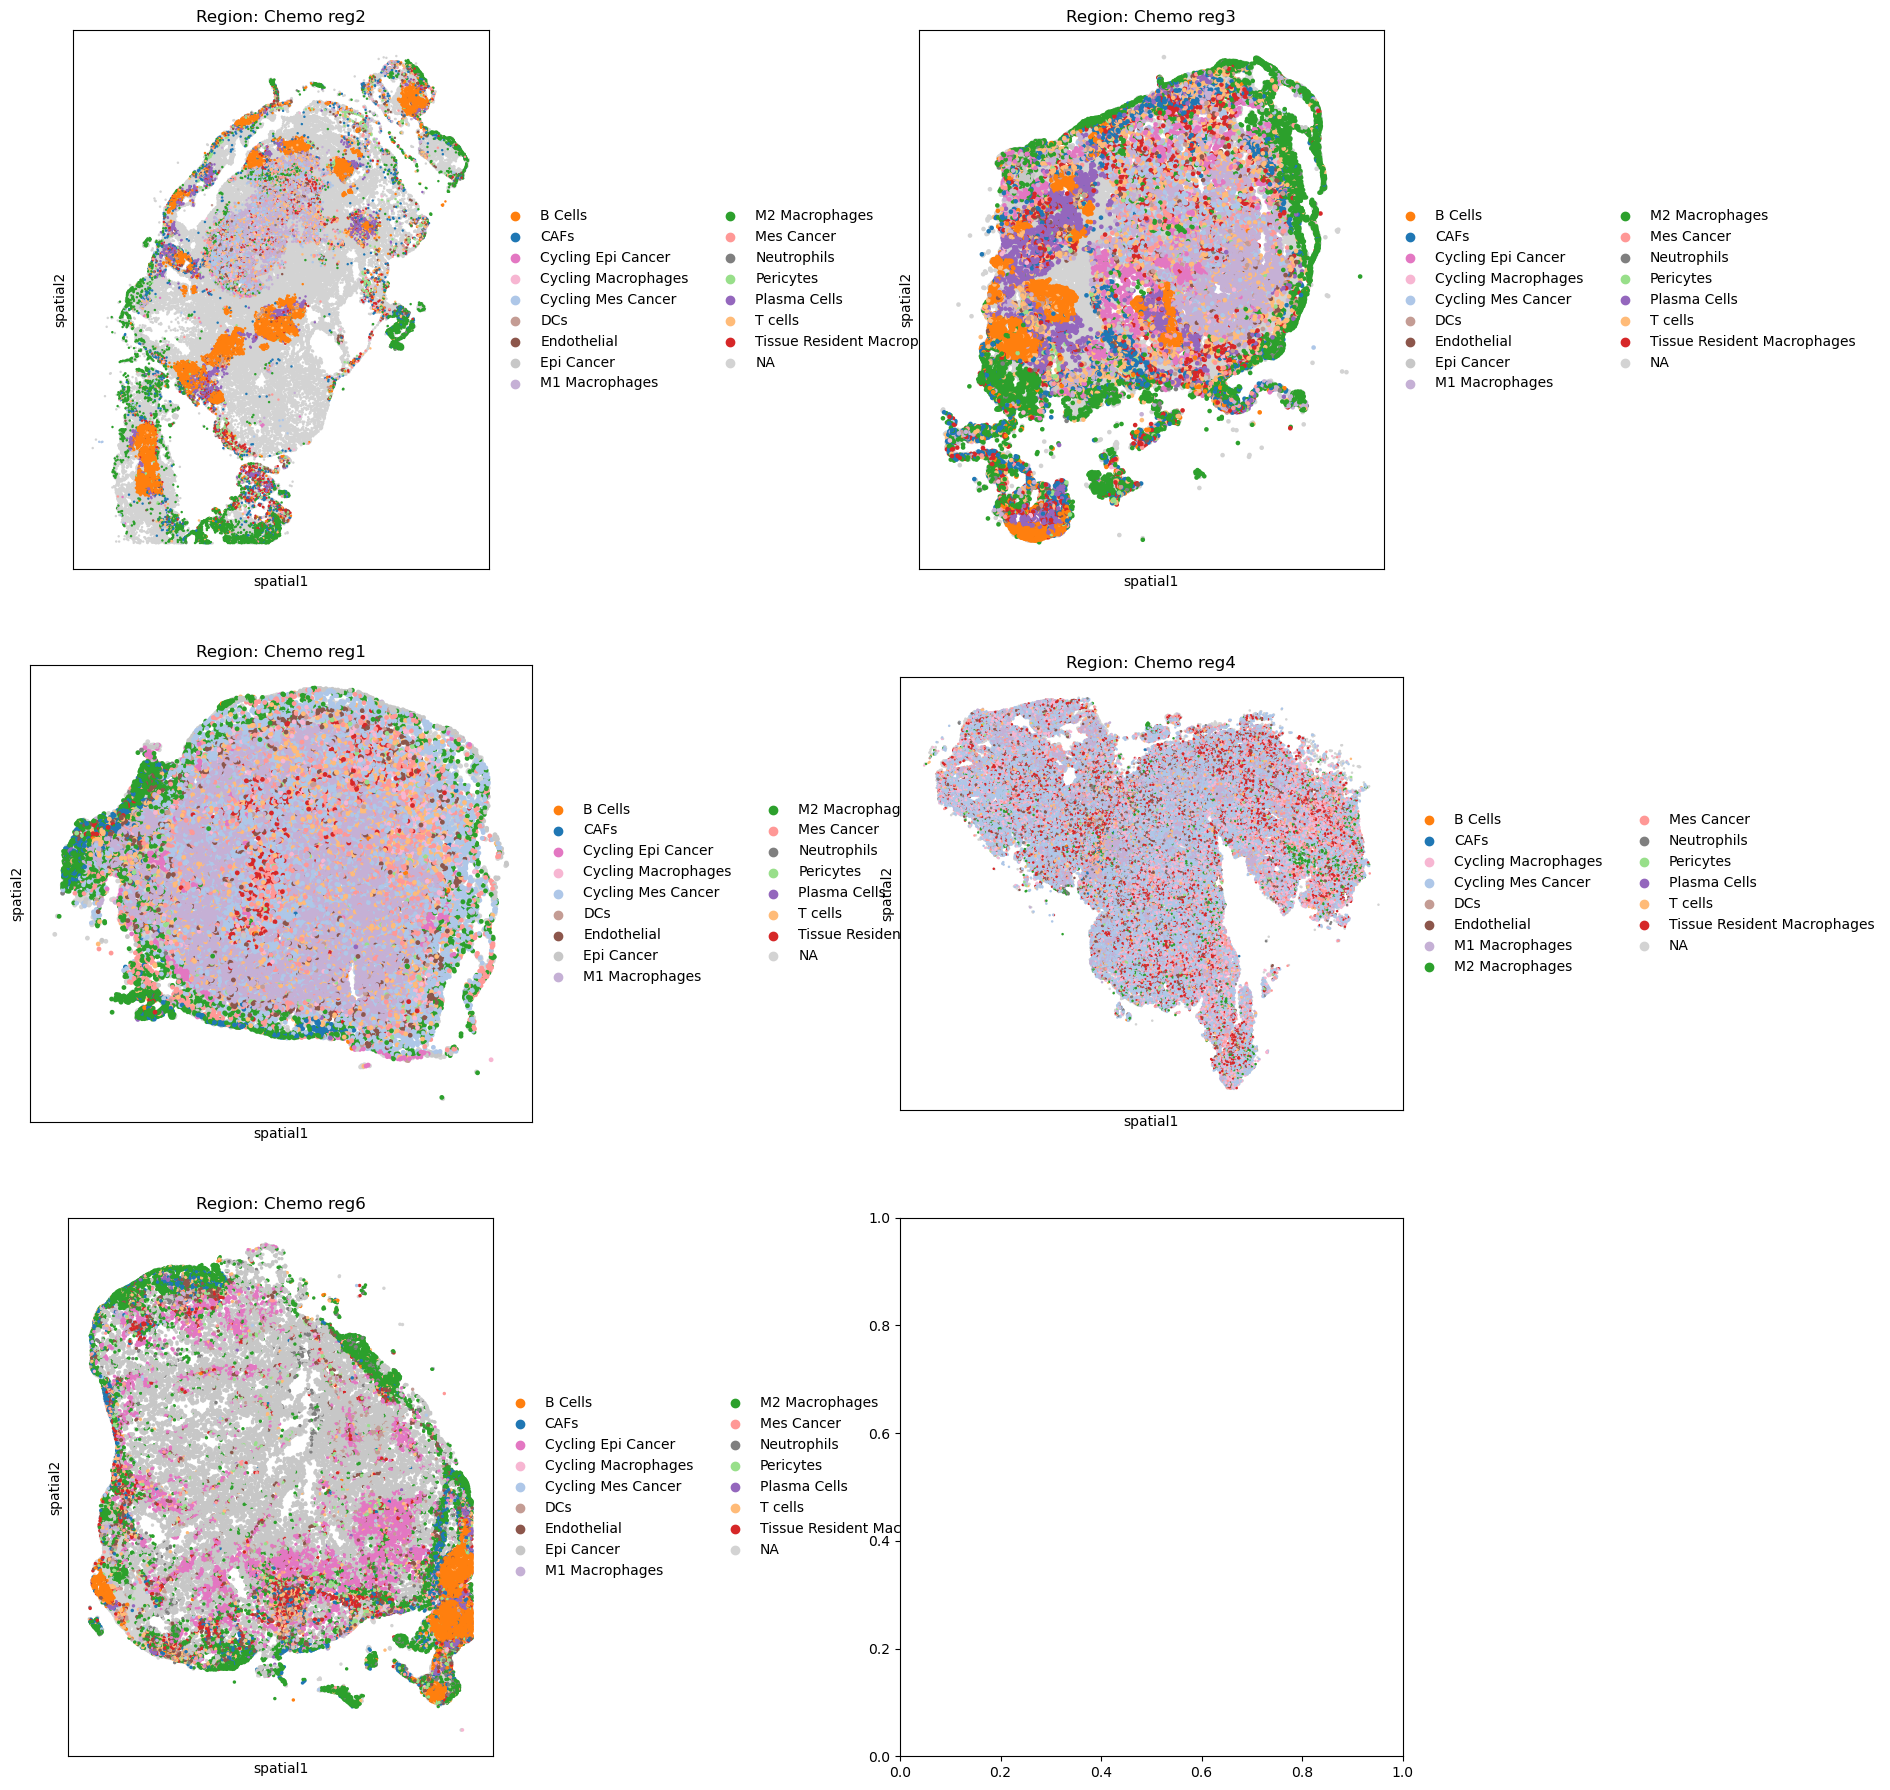

In [37]:
# Plot RCTD_first_filtered onto spatial spots 
regs = xen.obs['region'].unique()
# Set color palette 
labels = xen.obs["RCTD_first_filtered"].dropna().unique()
colors = plt.colormaps["tab20"].colors
palette = dict(zip(labels, colors))

# Create a 2x3 grid of subplots
fig, axes = plt.subplots(3,2, figsize=(18, 18))
axes = axes.flatten()

for i, reg_id in enumerate(regs):
    # Subset data for just this region
    subset = xen[xen.obs["region"] == reg_id].copy()
    
    # Plot on its own dedicated subplot axis
    sc.pl.spatial(
        subset, 
        color="RCTD_first_filtered", 
        palette = palette, 
        spot_size=30, 
        img_key=None, 
        ax=axes[i], 
        show=False,
        title=f"Region: {reg_id}"
    )

plt.tight_layout()
plt.savefig("../Plots/102826 Spatial Visulization RCTD_first_filtered.pdf", bbox_inches="tight",dpi=600)
plt.show()

Should I filtered out mis-mapping before running Spatial Query, or just run Spatial Query? First run SpatialQuery with RCTD_First_Filtered mapped cells, given only ~60% of the cells are mapped

In [14]:
xen.obs.head()

,cell_id,x,y,cell_area,samp,condition,region,Tumor Core,Cell Type,n_genes_by_counts,...,Tumor Distance,Mesenchymal Distance,Tumor Fraction,Mes Fraction,Macrophage Distance,RCTD_first_type,RCTD_spot_class,RCTD_first_filtered,Macrophage RCTD,RCTD_second_type
0,aaaahjjl-1,799.092346,6746.838379,191.236726,chemo1,chemo,Chemo reg2,Stroma,unknown,68,...,305.021081,357.937368,0.05,0.05,38.009683,CAFs,singlet,CAFs,NotMac,Mes Cancer 1
1,aaaajiam-1,816.627136,6738.786133,88.099847,chemo1,chemo,Chemo reg2,Stroma,unknown,43,...,318.672625,372.106212,0.05,0.05,23.866898,NaN,NaN,NaN,NotMac,NaN
2,aaaajjfc-1,825.193665,6753.208496,210.608758,chemo1,chemo,Chemo reg2,Stroma,unknown,68,...,311.693681,365.277906,0.05,0.05,16.819251,Cycling Mes Cancer 2,doublet_uncertain,Cycling Mes Cancer 2,NotMac,Tissue Resident Macrophages
3,aaabbjll-1,814.940186,6746.884766,117.270786,chemo1,chemo,Chemo reg2,Stroma,unknown,58,...,311.760065,365.120447,0.05,0.05,25.945406,B Cells,doublet_uncertain,B Cells,NotMac,Mes Cancer 2
4,aaabgicc-1,807.501282,6753.062012,136.733130,chemo1,chemo,Chemo reg2,Stroma,CD8,76,...,303.827129,356.956885,0.05,0.05,31.394812,T cells,doublet_certain,T cells,NotMac,Cycling Mes Cancer 1


In [12]:
rctd_classification = pd.read_csv("../RCTD/classification_df.txt",sep="\t")
rctd_classification.head()

,pixel,spot_class,first_type,second_type
1,0,singlet,CAFs,Mes Cancer 1
2,2,doublet_uncertain,Cycling Mes Cancer 2,Tissue Resident Macrophages
3,3,doublet_uncertain,B Cells,Mes Cancer 2
4,4,doublet_certain,T cells,Cycling Mes Cancer 1
5,5,singlet,M2 Macrophages,Plasma Cells


In [13]:
xen.obs['RCTD_second_type'] = xen.obs_names.map(rctd_classification.set_index('pixel')['second_type'])

In [15]:
rctd_macrophage_clusters = ["M1 Macrophages","M2 Macrophages","Cycling Macrophages","Tissue Resident Macrophages"]
rctd_mes_clusters = ['Cycling Mes Cancer 1','Cycling Mes Cancer 2','Mes Cancer 1','Mes Cancer 2']

1. If Macrophages were mapped to rctd_mes_clusters, what's the chance of second_type in rctd_macrophage_clusters?
2. If Mes Cancer was mapped to rctd_macrophage_clusters, what's the change of second_type in rctd_mes_clusters?

In [17]:
df = xen.obs.copy()

In [22]:
mac_mes = df[(df["cell_type"]=="Macrophages") & (df["RCTD_first_filtered"].isin(rctd_mes_clusters))]
(mac_mes["RCTD_second_type"].isin(rctd_macrophage_clusters)).sum()/mac_mes.shape[0]

np.float64(0.9725862690874113)

In [26]:
mes_mac = df[(df["cell_type"]=="Mes Cancer") & (df["RCTD_first_filtered"].isin(rctd_macrophage_clusters))]
(mes_mac["RCTD_second_type"].isin(rctd_mes_clusters)).sum()/mes_mac.shape[0]

np.float64(0.9971341728180634)

In [29]:
xen.obs = xen.obs.replace({
    "Mes Cancer 1": "Mes Cancer",
    "Mes Cancer 2": "Mes Cancer",
    'Cycling Mes Cancer 1':"Cycling Mes Cancer",
    'Cycling Mes Cancer 2':"Cycling Mes Cancer"
})

/tmp/ipykernel_1529131/2075065941.py:1: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  xen.obs = xen.obs.replace({


In [30]:
xen.obs.head()

,cell_id,x,y,cell_area,samp,condition,region,Tumor Core,Cell Type,n_genes_by_counts,...,Tumor Distance,Mesenchymal Distance,Tumor Fraction,Mes Fraction,Macrophage Distance,RCTD_first_type,RCTD_spot_class,RCTD_first_filtered,Macrophage RCTD,RCTD_second_type
0,aaaahjjl-1,799.092346,6746.838379,191.236726,chemo1,chemo,Chemo reg2,Stroma,unknown,68,...,305.021081,357.937368,0.05,0.05,38.009683,CAFs,singlet,CAFs,NotMac,Mes Cancer
1,aaaajiam-1,816.627136,6738.786133,88.099847,chemo1,chemo,Chemo reg2,Stroma,unknown,43,...,318.672625,372.106212,0.05,0.05,23.866898,NaN,NaN,NaN,NotMac,NaN
2,aaaajjfc-1,825.193665,6753.208496,210.608758,chemo1,chemo,Chemo reg2,Stroma,unknown,68,...,311.693681,365.277906,0.05,0.05,16.819251,Cycling Mes Cancer,doublet_uncertain,Cycling Mes Cancer,NotMac,Tissue Resident Macrophages
3,aaabbjll-1,814.940186,6746.884766,117.270786,chemo1,chemo,Chemo reg2,Stroma,unknown,58,...,311.760065,365.120447,0.05,0.05,25.945406,B Cells,doublet_uncertain,B Cells,NotMac,Mes Cancer
4,aaabgicc-1,807.501282,6753.062012,136.733130,chemo1,chemo,Chemo reg2,Stroma,CD8,76,...,303.827129,356.956885,0.05,0.05,31.394812,T cells,doublet_certain,T cells,NotMac,Cycling Mes Cancer


In [31]:
# Potentially relabel the cells? 
rctd_mes_clusters = ['Cycling Mes Cancer','Mes Cancer']

In [38]:
xen.obs["RCTD_corrected"] = xen.obs["RCTD_first_filtered"]
xen.obs.loc[(xen.obs["cell_type"]=="Macrophages") & (xen.obs["RCTD_first_filtered"].isin(rctd_mes_clusters))&(xen.obs["RCTD_second_type"].isin(rctd_macrophage_clusters)),'RCTD_corrected']=xen.obs['RCTD_second_type']
xen.obs.loc[(xen.obs["cell_type"]=="Mes Cancer") & (xen.obs["RCTD_first_filtered"].isin(rctd_macrophage_clusters))&(xen.obs["RCTD_second_type"].isin(rctd_mes_clusters)),'RCTD_corrected']=xen.obs['RCTD_second_type']


In [39]:
xen.obs.head()

,cell_id,x,y,cell_area,samp,condition,region,Tumor Core,Cell Type,n_genes_by_counts,...,Mesenchymal Distance,Tumor Fraction,Mes Fraction,Macrophage Distance,RCTD_first_type,RCTD_spot_class,RCTD_first_filtered,Macrophage RCTD,RCTD_second_type,RCTD_corrected
0,aaaahjjl-1,799.092346,6746.838379,191.236726,chemo1,chemo,Chemo reg2,Stroma,unknown,68,...,357.937368,0.05,0.05,38.009683,CAFs,singlet,CAFs,NotMac,Mes Cancer,CAFs
1,aaaajiam-1,816.627136,6738.786133,88.099847,chemo1,chemo,Chemo reg2,Stroma,unknown,43,...,372.106212,0.05,0.05,23.866898,NaN,NaN,NaN,NotMac,NaN,NaN
2,aaaajjfc-1,825.193665,6753.208496,210.608758,chemo1,chemo,Chemo reg2,Stroma,unknown,68,...,365.277906,0.05,0.05,16.819251,Cycling Mes Cancer,doublet_uncertain,Cycling Mes Cancer,NotMac,Tissue Resident Macrophages,Cycling Mes Cancer
3,aaabbjll-1,814.940186,6746.884766,117.270786,chemo1,chemo,Chemo reg2,Stroma,unknown,58,...,365.120447,0.05,0.05,25.945406,B Cells,doublet_uncertain,B Cells,NotMac,Mes Cancer,B Cells
4,aaabgicc-1,807.501282,6753.062012,136.733130,chemo1,chemo,Chemo reg2,Stroma,CD8,76,...,356.956885,0.05,0.05,31.394812,T cells,doublet_certain,T cells,NotMac,Cycling Mes Cancer,T cells


In [12]:
rctd_corrected = pd.crosstab(xen.obs['cell_type'], xen.obs['RCTD_corrected'])

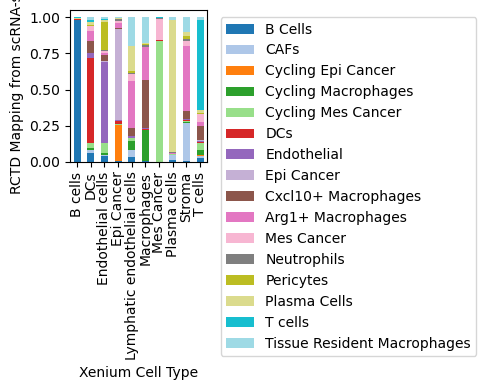

In [14]:
prop_table = rctd_corrected.div(rctd_corrected.sum(axis=1),axis=0)

prop_table.plot(
    kind="bar",
    stacked=True,
    figsize=(5, 4), 
    colormap='tab20'
)

plt.xlabel("Xenium Cell Type")
plt.ylabel("RCTD Mapping from scRNA-seq")
plt.legend(title="Cell Type RCTD Filtered")
plt.xticks(rotation=90)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.savefig("../Plots/102826_RCTD_Cell_Type_corrected.png", dpi=600, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [46]:
xen.write_h5ad('../objects/Graham_Chemo_Cell_Types_RCTD.h5ad')

### 2. SpatialQuery on RCTD labels

In [17]:
xen = sc.read_h5ad('../objects/Graham_Chemo_Cell_Types_RCTD.h5ad')

In [18]:
# filter for cells with RCTD_corrected label
xen = xen[xen.obs["RCTD_corrected"].notna()].copy()

In [82]:
# If excluding 'Chemo reg6'
xen = xen[xen.obs["region"]!='Chemo reg6'].copy()

In [19]:
xen.obs.head()

,cell_id,x,y,cell_area,samp,condition,region,Tumor Core,Cell Type,n_genes_by_counts,...,Mesenchymal Distance,Tumor Fraction,Mes Fraction,Macrophage Distance,RCTD_first_type,RCTD_spot_class,RCTD_first_filtered,Macrophage RCTD,RCTD_second_type,RCTD_corrected
0,aaaahjjl-1,799.092346,6746.838379,191.236726,chemo1,chemo,Chemo reg2,Stroma,unknown,68,...,357.937368,0.05,0.05,38.009683,CAFs,singlet,CAFs,NotMac,Mes Cancer,CAFs
2,aaaajjfc-1,825.193665,6753.208496,210.608758,chemo1,chemo,Chemo reg2,Stroma,unknown,68,...,365.277906,0.05,0.05,16.819251,Cycling Mes Cancer,doublet_uncertain,Cycling Mes Cancer,NotMac,Tissue Resident Macrophages,Cycling Mes Cancer
3,aaabbjll-1,814.940186,6746.884766,117.270786,chemo1,chemo,Chemo reg2,Stroma,unknown,58,...,365.120447,0.05,0.05,25.945406,B Cells,doublet_uncertain,B Cells,NotMac,Mes Cancer,B Cells
4,aaabgicc-1,807.501282,6753.062012,136.733130,chemo1,chemo,Chemo reg2,Stroma,CD8,76,...,356.956885,0.05,0.05,31.394812,T cells,doublet_certain,T cells,NotMac,Cycling Mes Cancer,T cells
5,aaabicdb-1,844.782227,6744.733398,107.200941,chemo1,chemo,Chemo reg2,Stroma,unknown,48,...,381.360441,0.05,0.05,NaN,M2 Macrophages,singlet,M2 Macrophages,M2 Macrophages,Plasma Cells,Arg1+ Macrophages


In [20]:
# Get log-normalized layer 
xen.X = xen.layers["lognorm"].copy()
xen.var["var_names"] = xen.var_names
# Split the object into adata datasets
adatas = []
dataset_names = []
for label in xen.obs["region"].unique():
    adatas.append(xen[xen.obs["region"] == label].copy())
    dataset_names.extend([label])

print(f"Total Regions: {len(adatas)}")
print(f"Total cells: {sum(a.n_obs for a in adatas):,}")

Total Regions: 5
Total cells: 192,238


In [21]:
# ---- Configuration: adjust these to match your dataset ----
spatial_key = "spatial"
label_key = "RCTD_corrected"
feature_name = "var_names"

In [22]:
spm = spatial_query_multi(
    adatas,
    datasets=dataset_names,
    spatial_key=spatial_key,
    label_key=label_key,
    feature_name=feature_name,
    build_gene_index=False,
    if_lognorm=False,
    if_normalize_spatial_coord=True,
)


Auto-normalizing spatial coordinates: mean nearest neighbor distance = 1.0
Scale factor: 0.1193
build_gene_index is False. Using adata.X for gene expression analysis.

Auto-normalizing spatial coordinates: mean nearest neighbor distance = 1.0
Scale factor: 0.1244
build_gene_index is False. Using adata.X for gene expression analysis.

Auto-normalizing spatial coordinates: mean nearest neighbor distance = 1.0
Scale factor: 0.1118
build_gene_index is False. Using adata.X for gene expression analysis.

Auto-normalizing spatial coordinates: mean nearest neighbor distance = 1.0
Scale factor: 0.1072
build_gene_index is False. Using adata.X for gene expression analysis.

Auto-normalizing spatial coordinates: mean nearest neighbor distance = 1.0
Scale factor: 0.1088
build_gene_index is False. Using adata.X for gene expression analysis.


In [23]:
valid_ds_names = sorted(set(d.split("_")[0] for d in spm.datasets))
print(valid_ds_names)

['Chemo reg1', 'Chemo reg2', 'Chemo reg3', 'Chemo reg4', 'Chemo reg6']


In [42]:
anchor_ct = 'Cycling Macrophages'
max_dist = 5
min_support = 0.5

motif_macrophage_df, motif_macrophage_motif_id, motif_macrophage_center_id = spm.motif_enrichment_dist(
    ct=anchor_ct,
    dataset=dataset_names,
    max_dist=max_dist,
    min_support=min_support,
    return_cellID=True
)

In [38]:
from SpatialQuery.plotting import plot_motif_enrichment_heatmap
plot_motif_enrichment_heatmap(enrich_df=motif_macrophage_df,
                              figsize=(5, 4),
                              save_path="../Plots/SpatialQuery/110226_Arg1+ Macrophages Anchor.pdf"
                              )

TypeError: plot_motif_enrichment_heatmap() got an unexpected keyword argument 'vmin'

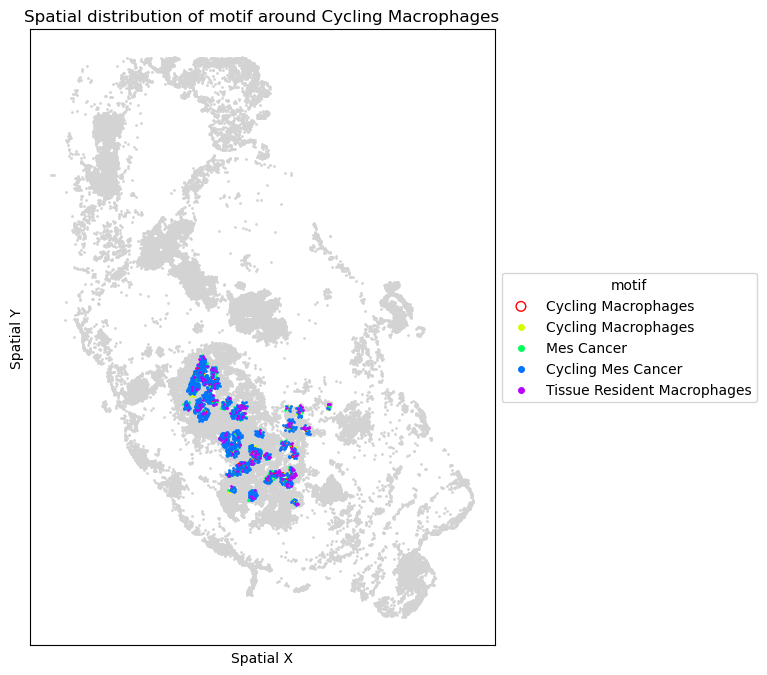

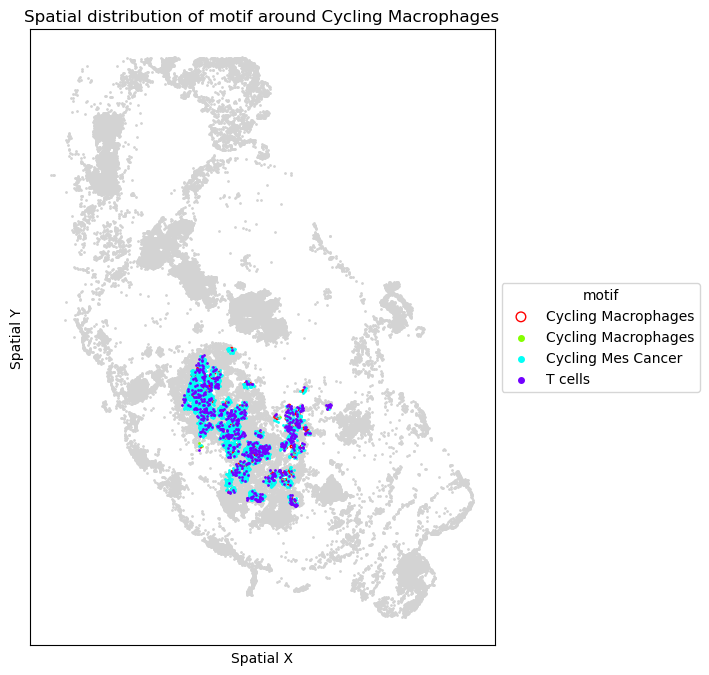

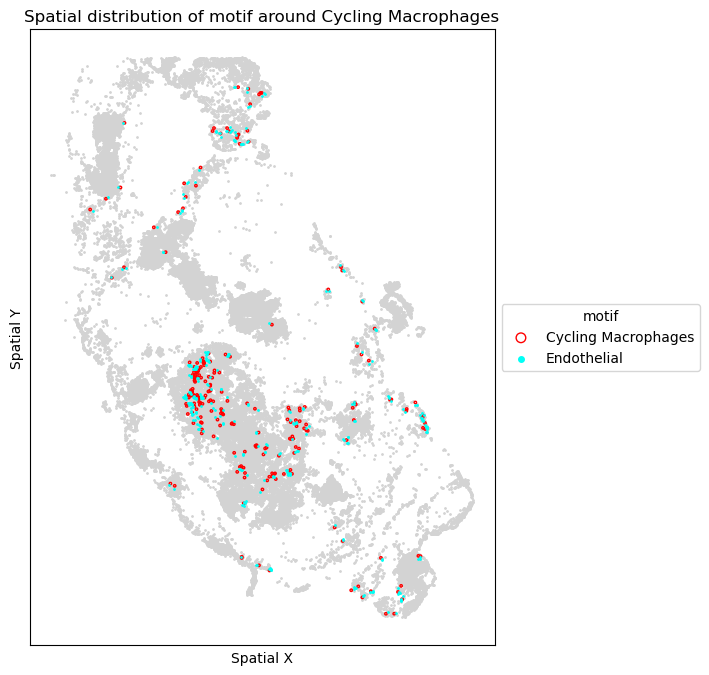

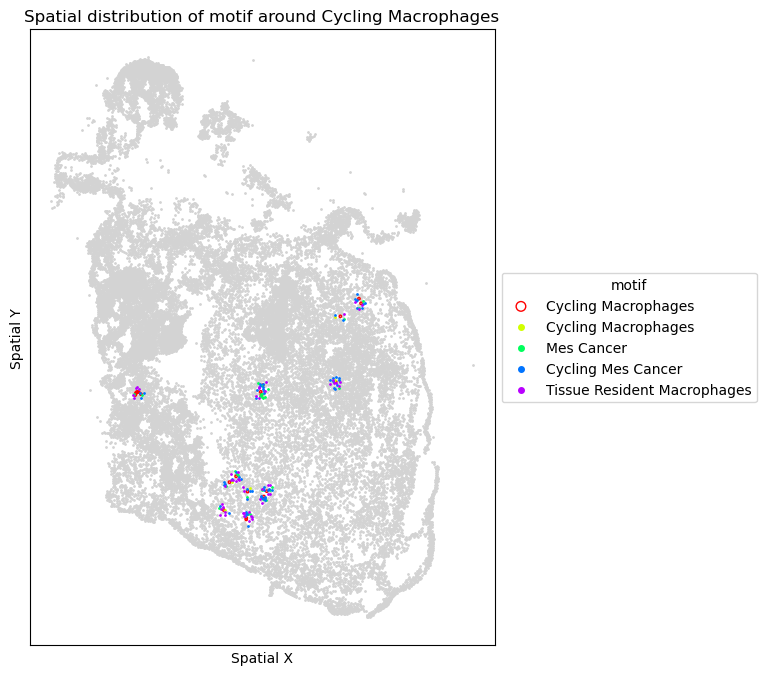

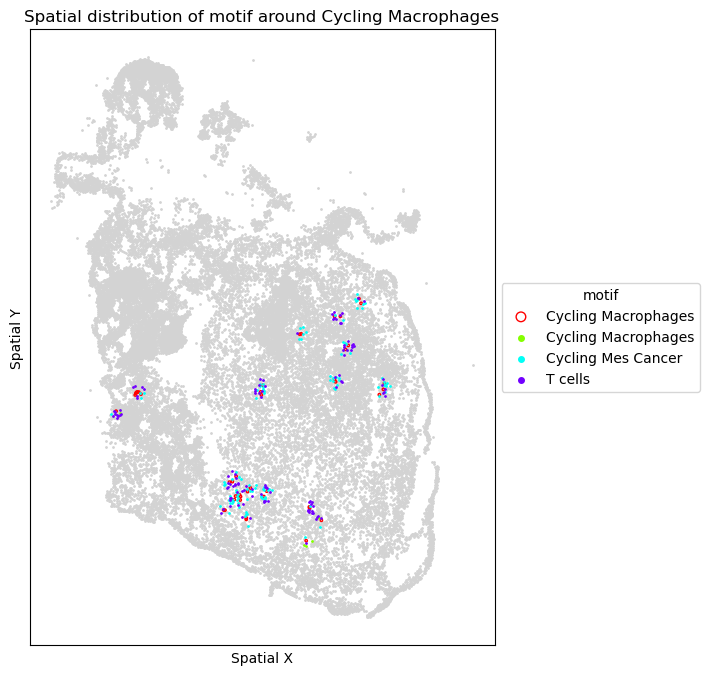

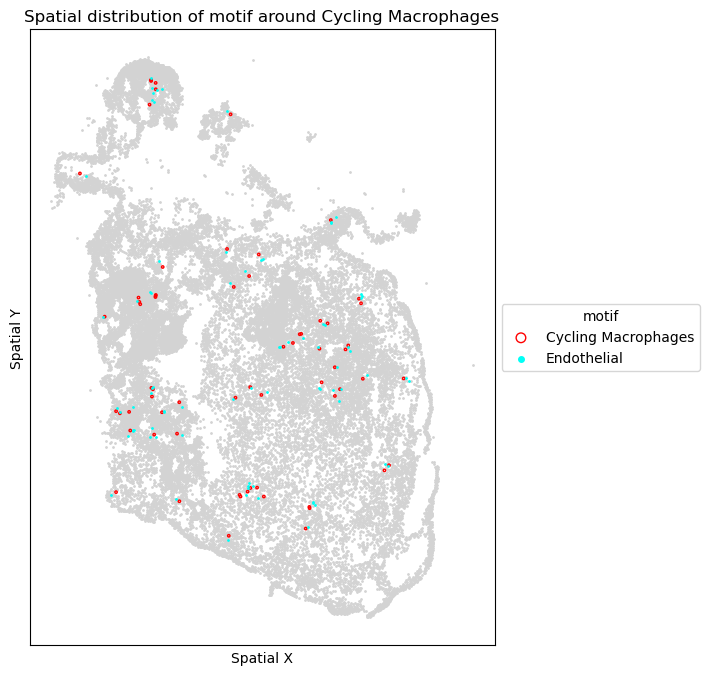

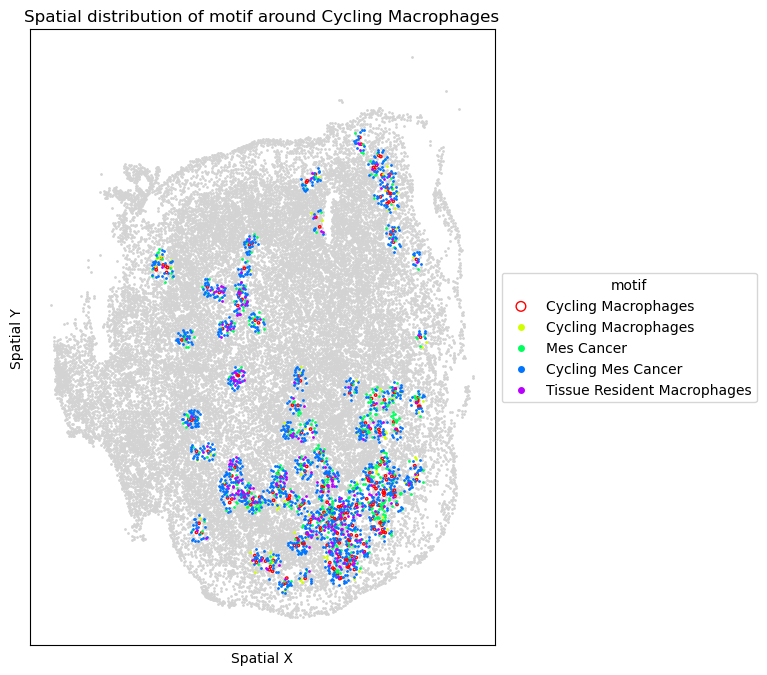

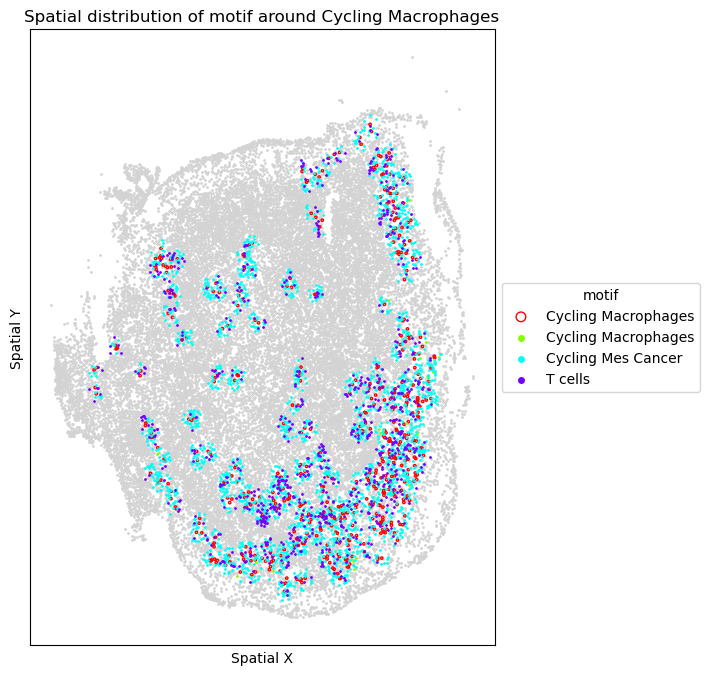

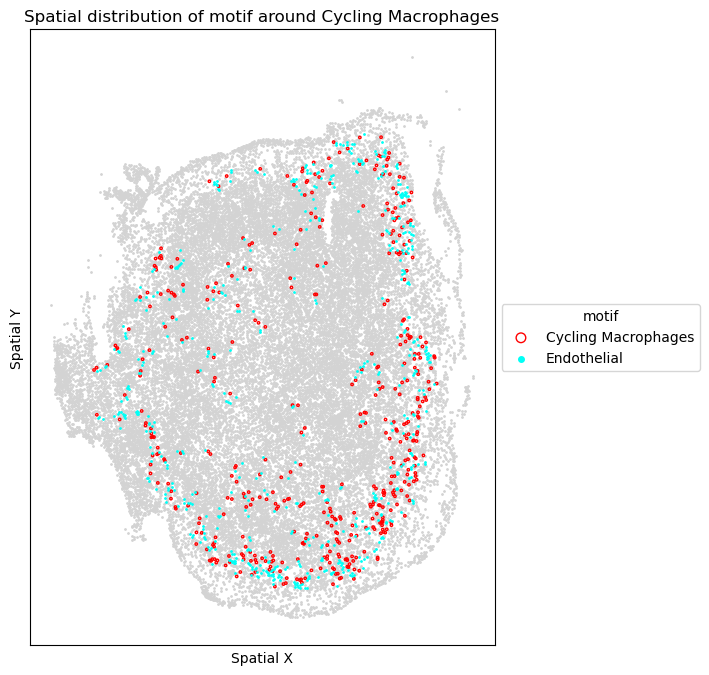

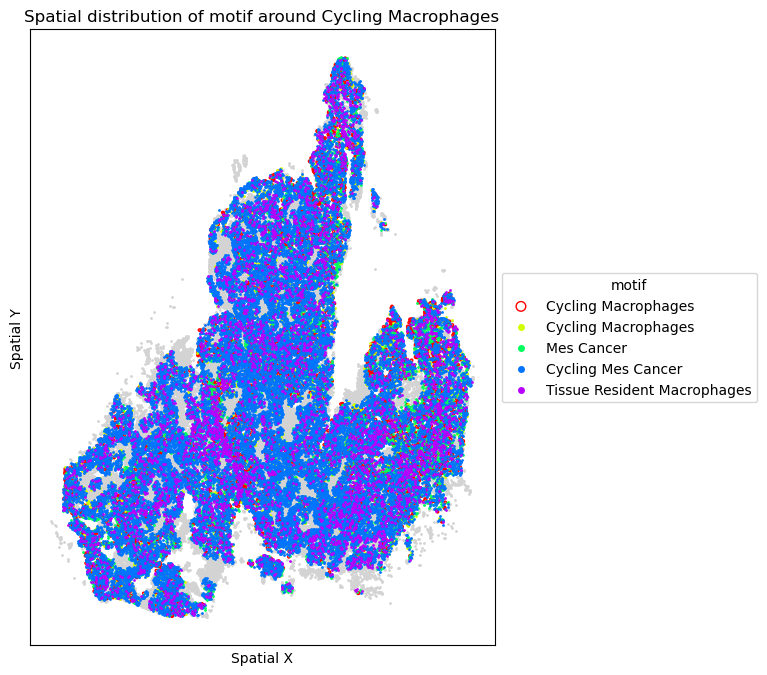

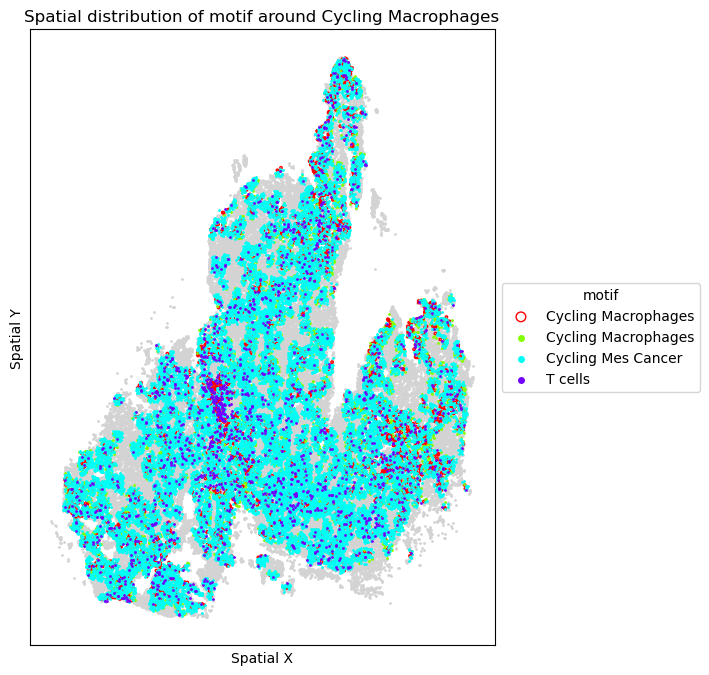

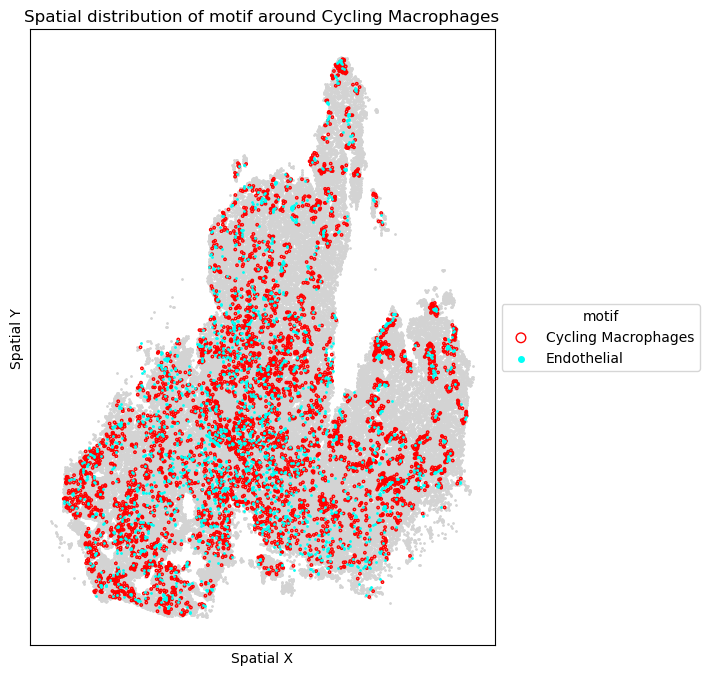

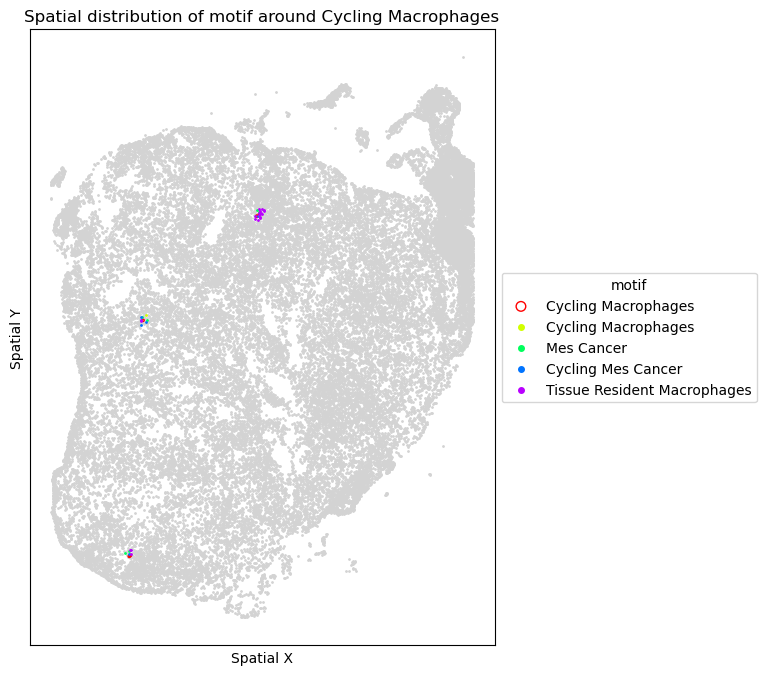

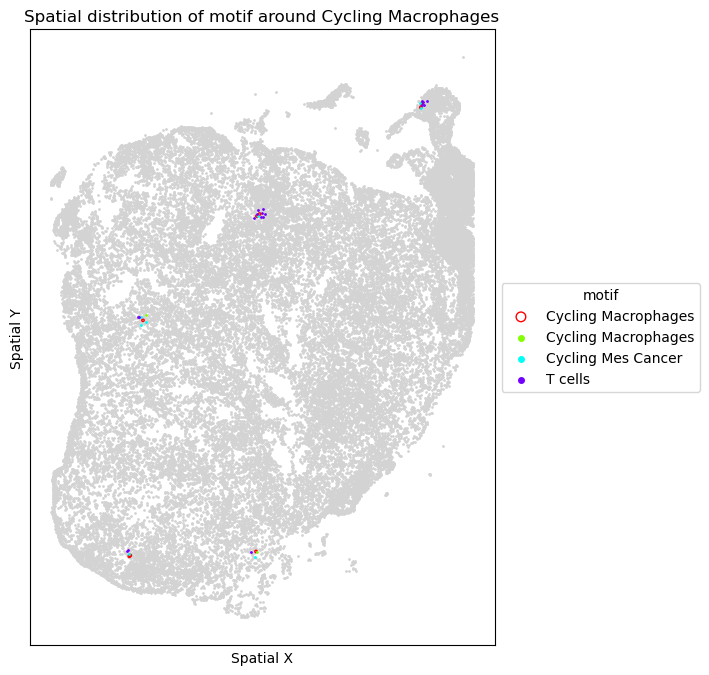

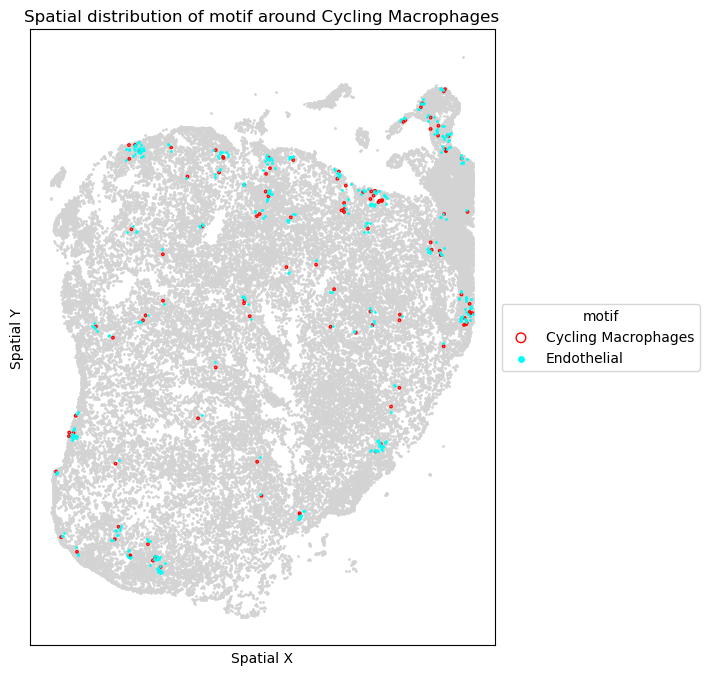

In [43]:
# Visualize motif distribution in a single slide 
for target_sp in spm.spatial_queries:
    for m in motif_macrophage_df["motifs"]:
        target_sp.plot_motif_celltype(
            ct=anchor_ct,
            motif=m,
            max_dist=max_dist,
            figsize=(6, 8),
        )

In [100]:
print(f"Anchor: {anchor_ct}, max_dist: {max_dist}")
print(f"Datasets: {dataset_names}")

Anchor: M2 Macrophages, max_dist: 5
Datasets: ['Chemo reg2', 'Chemo reg3', 'Chemo reg1', 'Chemo reg4', 'Chemo reg6']


In [108]:
motif2 = ['CAFs',"M2 Macrophages"]
covarying_genes_m2 = spm.compute_gene_gene_correlation_by_type(
    ct=anchor_ct,
    motif=motif2,
    dataset=dataset_names,
    max_dist=max_dist,
)

Computing covarying genes using expression data ...
Only one non-center cell type in motif: ['CAFs']. Using compute_gene_gene_correlation method.
No genes specified. Using union of genes across all selected FOVs ...
Gene coverage: 300 genes in all FOVs, 300 genes total (union)
Analyzing 300 genes across 5 FOVs

Step 1: Computing and accumulating statistics across FOVs

--- Processing FOV 1/5: Chemo reg2_0 ---
  FOV has 300/300 genes from analysis list
Removed 98567 duplicate pairs (87.4%)
  Corr1: 14250 center-neighbor pairs
  Corr2: 3118 centers × 777 non-neighbors
  Corr3: 6837 no-motif pairs

--- Processing FOV 2/5: Chemo reg3_0 ---
  FOV has 300/300 genes from analysis list
Removed 234485 duplicate pairs (88.1%)
  Corr1: 31650 center-neighbor pairs
  Corr2: 4098 centers × 608 non-neighbors
  Corr3: 7376 no-motif pairs

--- Processing FOV 3/5: Chemo reg1_0 ---
  FOV has 300/300 genes from analysis list
Removed 179274 duplicate pairs (90.3%)
  Corr1: 19158 center-neighbor pairs
  Cor

In [109]:
covarying_genes_m2 = covarying_genes_m2[covarying_genes_m2['if_significant']]
covarying_genes_m2

,gene_center,gene_motif,corr_neighbor,corr_non_neighbor,p_value_test1,delta_corr_test1,corr_center_no_motif,p_value_test2,delta_corr_test2,combined_score,adj-pval-test1,adj-pval-test2,if_significant,cell_type
0,Krt5,Krt5,0.375951,-0.013067,0.000000e+00,0.389018,0.142291,0.000000e+00,0.233659,84.080052,0.000000e+00,0.000000e+00,True,CAFs
1,Dcn,Arg1,0.191619,-0.045670,2.220446e-15,0.237289,-0.188611,0.000000e+00,0.380231,80.891565,6.630463e-12,0.000000e+00,True,CAFs
2,C1s1,Arg1,0.177414,-0.046838,7.660539e-14,0.224252,-0.201647,0.000000e+00,0.379061,80.485245,1.883832e-10,0.000000e+00,True,CAFs
11,Il1r1,Arg1,0.124941,-0.026491,4.974961e-07,0.151432,-0.090400,0.000000e+00,0.215341,45.508031,2.220426e-04,0.000000e+00,True,CAFs
12,Pdgfra,Arg1,0.158615,-0.030951,2.775482e-10,0.189566,-0.054297,0.000000e+00,0.212912,45.255006,3.026868e-07,0.000000e+00,True,CAFs
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
89987,Epcam,Arg1,-0.091684,0.027266,8.131767e-05,-0.118950,0.083006,3.108624e-15,-0.174689,-1.919950,1.529016e-02,8.860710e-12,True,CAFs
89990,Cd24a,Arg1,-0.085035,0.028558,1.687433e-04,-0.113593,0.095261,4.440892e-16,-0.180296,-2.066173,2.668739e-02,1.428100e-12,True,CAFs
89997,mCherry,Arg1,-0.116257,0.055727,1.169756e-08,-0.171985,0.142945,0.000000e+00,-0.259202,-54.841641,8.195872e-06,0.000000e+00,True,CAFs
89998,Myc,Arg1,-0.086180,0.037481,4.219667e-05,-0.123661,0.203295,0.000000e+00,-0.289475,-60.952086,9.077423e-03,0.000000e+00,True,CAFs


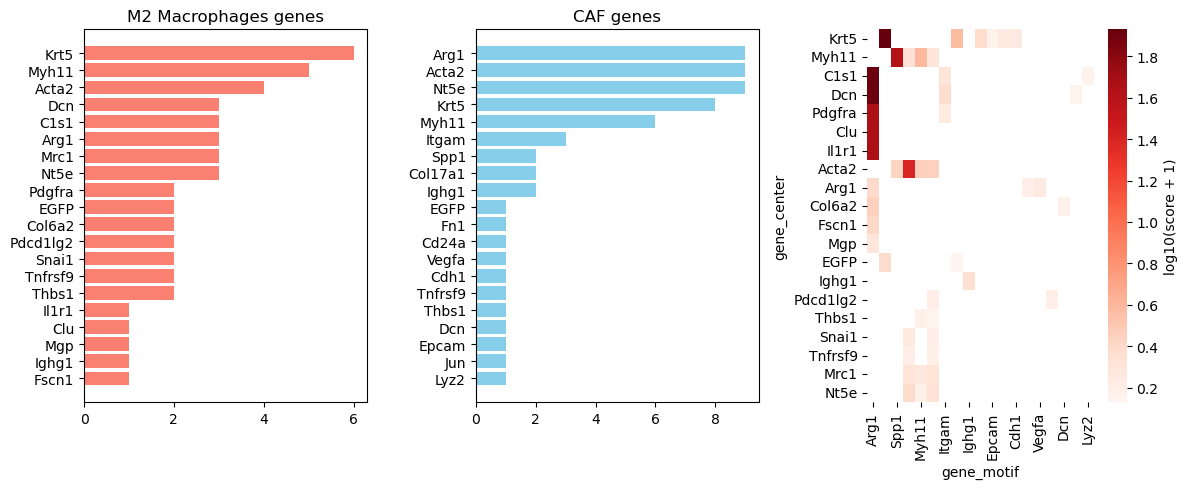

In [110]:
# Covarying gene pairs for motif2 (between Mes Cancer and Macrophages)
oligo_pos = covarying_genes_m2[covarying_genes_m2['cell_type'] == 'CAFs'].copy()
oligo_pos = oligo_pos[oligo_pos['combined_score'] > 0]

top_gene_center = pd.DataFrame(oligo_pos['gene_center'].value_counts().head(20))[::-1]
top_gene_motif = pd.DataFrame(oligo_pos['gene_motif'].value_counts().head(20))[::-1]

fig, axs = plt.subplots(1, 3, figsize=(12, 5))

axs[0].barh(top_gene_center.index.tolist(), top_gene_center['count'].tolist(), color='salmon')
axs[0].set_title(f'{anchor_ct} genes')

axs[1].barh(top_gene_motif.index.tolist(), top_gene_motif['count'].tolist(), color='skyblue')
axs[1].set_title('CAF genes')

# Heatmap of top50 gene pairs
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import pdist

top20_center = oligo_pos['gene_center'].value_counts().head(20).index.tolist()
top20_motif = oligo_pos['gene_motif'].value_counts().head(20).index.tolist()
sub = oligo_pos[oligo_pos['gene_center'].isin(top20_center) & oligo_pos['gene_motif'].isin(top20_motif)]

pivot = sub.pivot_table(index='gene_center', columns='gene_motif', values='combined_score', fill_value=0)
mask = (pivot == 0)
data = np.log10(pivot + 1)

row_order = dendrogram(linkage(pdist(data), method='average'), no_plot=True)['leaves']
col_order = dendrogram(linkage(pdist(data.T), method='average'), no_plot=True)['leaves']

sns.heatmap(
    data.iloc[row_order, col_order],
    mask=mask.iloc[row_order, col_order],
    cmap='Reds',
    cbar_kws={'label': 'log10(score + 1)'},
    ax=axs[2],
)

plt.tight_layout()

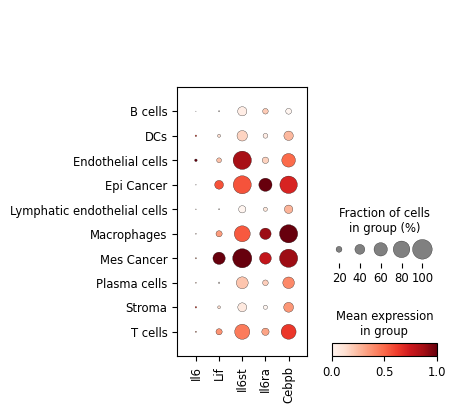

In [119]:
# Are IL6 family genes enriched near Cebpb-high macrophages
dp = sc.pl.dotplot(
    xen, 
    var_names= ['Il6','Lif','Il6st','Il6ra','Cebpb'], 
    groupby='cell_type',        # Column name in adata.obs for cell types
    cmap='Reds',             # Color map for average expression
    expression_cutoff=0.0,    # Threshold for counting a cell as "expressing"
    colorbar_title='Mean expression\nin group',
    size_title='Fraction of cells\nin group (%)',
    standard_scale='var',
    return_fig = True)
dp.savefig('../Plots/Il6_family_genes_cell_types.pdf', bbox_inches='tight')

### 4. Try a permutation test and Spearman correlation for what genes are enriched near M2 macrophages

In [127]:
xen.X = xen.layers["lognorm"].copy()

In [120]:
# Plot gene expression levels based on how close the nearest 3 tumor cells are
from sklearn.neighbors import NearestNeighbors
neighbors = 3
m2 = xen[xen.obs['RCTD_corrected']=='M2 Macrophages']
for reg in tqdm(xen.obs['region'].unique()): # Each slide is one region
    xen_reg = xen[xen.obs['region']==reg].obs # Get that slide
    m2_reg = m2[m2.obs['region']==reg].obs
    non_m2 = xen_reg.drop(m2_reg.index,axis=0) # Remove M2 Macrophages from all cells in Slide
    if len(m2_reg) < 3: # If fewer than 3 tumor cells in Slide
        xen.obs.loc[non_m2.index,'M2 Distance']= np.inf 
        continue
    non_pts = non_m2.loc[:,['x','y']].values
    m2_pts = m2_reg.loc[:,['x','y']].values
    tree = NearestNeighbors(n_neighbors=neighbors)
    tree.fit(m2_pts) # Unsupervised for nearest neighbor searches
    distances, indices = tree.kneighbors(non_pts)
    # Get average neighbor_distances
    avg_distances = np.mean(distances,axis=1)
    print(avg_distances.shape)
    xen.obs.loc[non_m2.index,'M2 Distance'] = avg_distances

  0%|          | 0/5 [00:00<?, ?it/s]

(95371,)
(36760,)
(31470,)
(89576,)
(45873,)


In [121]:
xen.obs.head()

,cell_id,x,y,cell_area,samp,condition,region,Tumor Core,Cell Type,n_genes_by_counts,...,Tumor Fraction,Mes Fraction,Macrophage Distance,RCTD_first_type,RCTD_spot_class,RCTD_first_filtered,Macrophage RCTD,RCTD_second_type,RCTD_corrected,M2 Distance
0,aaaahjjl-1,799.092346,6746.838379,191.236726,chemo1,chemo,Chemo reg2,Stroma,unknown,68,...,0.05,0.05,38.009683,CAFs,singlet,CAFs,NotMac,Mes Cancer,CAFs,34.926205
1,aaaajiam-1,816.627136,6738.786133,88.099847,chemo1,chemo,Chemo reg2,Stroma,unknown,43,...,0.05,0.05,23.866898,NaN,NaN,NaN,NotMac,NaN,NaN,31.670366
2,aaaajjfc-1,825.193665,6753.208496,210.608758,chemo1,chemo,Chemo reg2,Stroma,unknown,68,...,0.05,0.05,16.819251,Cycling Mes Cancer,doublet_uncertain,Cycling Mes Cancer,NotMac,Tissue Resident Macrophages,Cycling Mes Cancer,26.292440
3,aaabbjll-1,814.940186,6746.884766,117.270786,chemo1,chemo,Chemo reg2,Stroma,unknown,58,...,0.05,0.05,25.945406,B Cells,doublet_uncertain,B Cells,NotMac,Mes Cancer,B Cells,31.418133
4,aaabgicc-1,807.501282,6753.062012,136.733130,chemo1,chemo,Chemo reg2,Stroma,CD8,76,...,0.05,0.05,31.394812,T cells,doublet_certain,T cells,NotMac,Cycling Mes Cancer,T cells,29.390337


In [131]:
from scipy.stats import spearmanr
def spearman_correlations(macrophages_sub,distance_metric):
    """
    Calculate Spearman correlations between gene expression in macrophages and the distance from nearest 3 tumor cells. 
    """
    y = macrophages_sub.obs[distance_metric]
    corr_coef = np.zeros(len(macrophages_sub.var_names))
    p_values = np.zeros(len(macrophages_sub.var_names))
    for i, gene in enumerate(macrophages_sub.var_names):
        expr = macrophages_sub[:,gene].to_df()
        correlation,pval = spearmanr(expr,y)
        corr_coef[i] = correlation
        p_values[i] = pval
    coef_df = pd.DataFrame({"Gene":macrophages_sub.var_names, "Coefficient":corr_coef, "Absolute Coef": np.abs(corr_coef), 'p-value':p_values})
    coef_df = coef_df.sort_values(by="Coefficient", ascending=True)
    return coef_df

In [128]:
xen_subset = xen[xen.obs["M2 Distance"].notna() & ~np.isinf(xen.obs["M2 Distance"])].copy()

In [132]:
coef_df = spearman_correlations(xen_subset, "M2 Distance") 
coef_df.head(50)

,Gene,Coefficient,Absolute Coef,p-value
5,Arg1,-0.414702,0.414702,0.000000e+00
183,Krt5,-0.218087,0.218087,0.000000e+00
95,Fn1,-0.196685,0.196685,0.000000e+00
65,Col17a1,-0.180281,0.180281,0.000000e+00
55,Cdh1,-0.169992,0.169992,0.000000e+00
57,Cebpb,-0.165326,0.165326,0.000000e+00
162,Itgam,-0.164290,0.164290,0.000000e+00
46,Cd44,-0.164223,0.164223,0.000000e+00
282,Ubc,-0.160382,0.160382,0.000000e+00
217,Pdpn,-0.159260,0.159260,0.000000e+00


In [149]:
coef_df.sort_values(by="Coefficient", ascending=False).head(50)

,Gene,Coefficient,Absolute Coef,p-value
198,Mpo,0.181439,0.181439,0.000000e+00
212,Pax5,0.176724,0.176724,0.000000e+00
49,Cd79a,0.176108,0.176108,0.000000e+00
34,Cd19,0.173694,0.173694,0.000000e+00
92,Fcer2a,0.171460,0.171460,0.000000e+00
239,Rorc,0.169276,0.169276,0.000000e+00
267,Tnfrsf13c,0.154210,0.154210,0.000000e+00
82,Cxcr5,0.148941,0.148941,0.000000e+00
200,Ms4a1,0.142212,0.142212,0.000000e+00
104,H2-Aa,0.138915,0.138915,0.000000e+00


In [138]:
def label_nearest_neighbors(xen,groupby, cell_type):
    """
    Given cell_type, identify 20 nearest neighbors to this cell type 
    """
    from sklearn.neighbors import NearestNeighbors
    neighbors = 20
    m2 = xen[xen.obs[groupby]==cell_type]
    xen.obs["M2 Neighbors"] = "NotM2 Neighbors"
    for reg in tqdm(xen.obs['region'].unique()): # Each slide is one region
        xen_reg = xen[xen.obs['region']==reg].obs # Get that slide
        m2_reg = m2[m2.obs['region']==reg].obs
        non_m2 = xen_reg.drop(m2_reg.index,axis=0) # Remove M2 Macrophages from all cells in Slide
        # Fit nearest neighbors
        non_pts = non_m2.loc[:,['x','y']].values
        m2_pts = m2_reg.loc[:,['x','y']].values
        tree = NearestNeighbors(n_neighbors=neighbors)
        tree.fit(non_pts) # Unsupervised for nearest neighbor searches
        distances, indices = tree.kneighbors(m2_pts)
        # Label the neighbors
        unique_positional_idx = np.unique(indices.flatten())
        neighbor_pandas_labels = non_m2.index[unique_positional_idx]
        xen.obs.loc[neighbor_pandas_labels, "M2 Neighbors"] = "M2 Neighbors"
    return xen.copy()

In [139]:
xen = label_nearest_neighbors(xen,'RCTD_corrected','M2 Macrophages')

  0%|          | 0/5 [00:00<?, ?it/s]

In [141]:
xen.obs["M2 Neighbors"].value_counts()

M2 Neighbors
NotM2 Neighbors    245376
M2 Neighbors        72798
Name: count, dtype: int64

In [143]:
xen_subset = xen[xen.obs['RCTD_corrected']!='M2 Macrophages'].copy()

In [147]:
sc.tl.rank_genes_groups(
    xen_subset,
    groupby="M2 Neighbors",
    groups=["NotM2 Neighbors"],
    reference="M2 Neighbors",
    method="wilcoxon"   # or "t-test", "logreg"
)

In [148]:
de = sc.get.rank_genes_groups_df(xen_subset, group=["NotM2 Neighbors"])
de.head(50)

,names,scores,logfoldchanges,pvals,pvals_adj
0,H2-Aa,75.797852,1.066593,0.000000e+00,0.000000e+00
1,H2-Ab1,63.996861,0.919393,0.000000e+00,0.000000e+00
2,H2-Eb1,63.093517,0.995914,0.000000e+00,0.000000e+00
3,Icosl,55.857037,1.077085,0.000000e+00,0.000000e+00
4,Cd79a,55.843292,2.648645,0.000000e+00,0.000000e+00
5,Psmb8,54.013168,0.416681,0.000000e+00,0.000000e+00
6,Tap1,53.878670,0.457447,0.000000e+00,0.000000e+00
7,Cxcl9,53.550632,1.165047,0.000000e+00,0.000000e+00
8,Cd19,51.981506,2.607783,0.000000e+00,0.000000e+00
9,Cxcl10,49.566521,1.002623,0.000000e+00,0.000000e+00


In [ ]:
nn = NearestNeighbors(n_neighbors=20)
nn.fit(coords[is_not_m2])

# 3. Find the 20 closest non-M2 cells for EACH M2 macrophage
# returns indices relative to the 'is_not_m2' subset
_, subset_neighbor_idx = nn.kneighbors(coords[is_m2])

### 5. Further Examination of Macrophage Subsets

In [4]:
xen = sc.read_h5ad('../objects/Graham_Chemo_Cell_Types_RCTD.h5ad')
xen.obs.head()

,cell_id,x,y,cell_area,samp,condition,region,Tumor Core,Cell Type,n_genes_by_counts,...,Mesenchymal Distance,Tumor Fraction,Mes Fraction,Macrophage Distance,RCTD_first_type,RCTD_spot_class,RCTD_first_filtered,Macrophage RCTD,RCTD_second_type,RCTD_corrected
0,aaaahjjl-1,799.092346,6746.838379,191.236726,chemo1,chemo,Chemo reg2,Stroma,unknown,68,...,357.937368,0.05,0.05,38.009683,CAFs,singlet,CAFs,NotMac,Mes Cancer,CAFs
1,aaaajiam-1,816.627136,6738.786133,88.099847,chemo1,chemo,Chemo reg2,Stroma,unknown,43,...,372.106212,0.05,0.05,23.866898,NaN,NaN,NaN,NotMac,NaN,NaN
2,aaaajjfc-1,825.193665,6753.208496,210.608758,chemo1,chemo,Chemo reg2,Stroma,unknown,68,...,365.277906,0.05,0.05,16.819251,Cycling Mes Cancer,doublet_uncertain,Cycling Mes Cancer,NotMac,Tissue Resident Macrophages,Cycling Mes Cancer
3,aaabbjll-1,814.940186,6746.884766,117.270786,chemo1,chemo,Chemo reg2,Stroma,unknown,58,...,365.120447,0.05,0.05,25.945406,B Cells,doublet_uncertain,B Cells,NotMac,Mes Cancer,B Cells
4,aaabgicc-1,807.501282,6753.062012,136.733130,chemo1,chemo,Chemo reg2,Stroma,CD8,76,...,356.956885,0.05,0.05,31.394812,T cells,doublet_certain,T cells,NotMac,Cycling Mes Cancer,T cells


In [5]:
import sys
sys.path.append('../')
from get_tumor_areas import get_area_main

In [33]:
s = xen[xen.obs['region']=='Chemo reg3']

In [28]:
s.obs['Tumor Coreb'] = (s.obs['Tumor Core']=='Intratumoral').astype(int)

/tmp/ipykernel_2992683/3369552408.py:1: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  s.obs['Tumor Coreb'] = (s.obs['Tumor Core']=='Intratumoral').astype(int)


In [32]:
s.obs['Tumor Coreb'].value_counts()

Tumor Coreb
0    90540
1     9132
Name: count, dtype: int64

(10416.69580078125, 3838.08349609375)

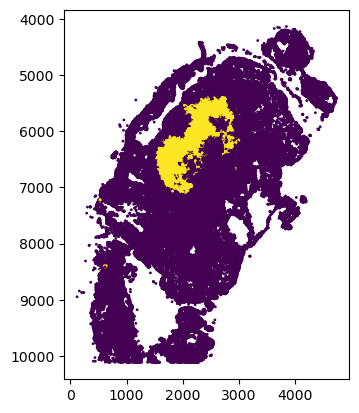

In [29]:
plt.scatter(*s.obs.loc[:,['x','y']].values.T,s=1,c = s.obs['Tumor Coreb']==1)
plt.gca().set_aspect('equal')
plt.ylim(*plt.ylim()[::-1])

In [6]:
areas = get_area_main(xen,tumor_col = 'Mesenchymal Core',to_plot=False,resolution_mpp = 1,
                      x='x',y='y',path_col='region')

/home/nig060/miniconda3/envs/python3.10/lib/python3.10/site-packages/pandas/core/indexing.py:1858: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  self.obj[key] = value
/n/data2/dfci/cancerimm/wucherpfennig/Alexa/nig060/Xenium/Analysis/../get_tumor_areas.py:101: DeprecationWarning: `in1d` is deprecated. Use `np.isin` instead.
  areas_dict[label] = areas[np.in1d(tumor_label,[2,3])].sum()
/n/data2/dfci/cancerimm/wucherpfennig/Alexa/nig060/Xenium/Analysis/../get_tumor_areas.py:101: DeprecationWarning: `in1d` is deprecated. Use `np.isin` instead.
  areas_dict[label] = areas[np.in1d(tumor_label,[2,3])].sum()
/home/nig060/miniconda3/envs/python3.10/lib/python3.10/site-packages/pandas/core/indexing.py:1858: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  self.obj[key] = value
/n/data2/dfci/cancerimm/wucherpfennig/Alexa/nig060/Xenium/Analysis/../get_tumor_areas.py:101: DeprecationWarni

In [7]:
areas

,Stroma,Intratumoral
Chemo reg2,11.112639,1.668053
Chemo reg3,3.928257,0.612088
Chemo reg1,0.804705,3.836001
Chemo reg4,0.607654,11.586452
Chemo reg6,9.394039,0.000020


In [ ]:
# Identify Stroma/Mesenchymal/Epithelial Areas, calculate what percentage 

In [3]:
tumor = xen[xen.obs["cell_type"].isin(["Mes Cancer", "Epi Cancer"])].copy()

In [4]:
sc.pp.neighbors(tumor, use_rep="X_pca_harmony")
sc.tl.umap(tumor, min_dist=0.1)
sc.tl.leiden(tumor, resolution=0.2)

/tmp/ipykernel_3404995/1234309615.py:3: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(tumor, resolution=0.2)


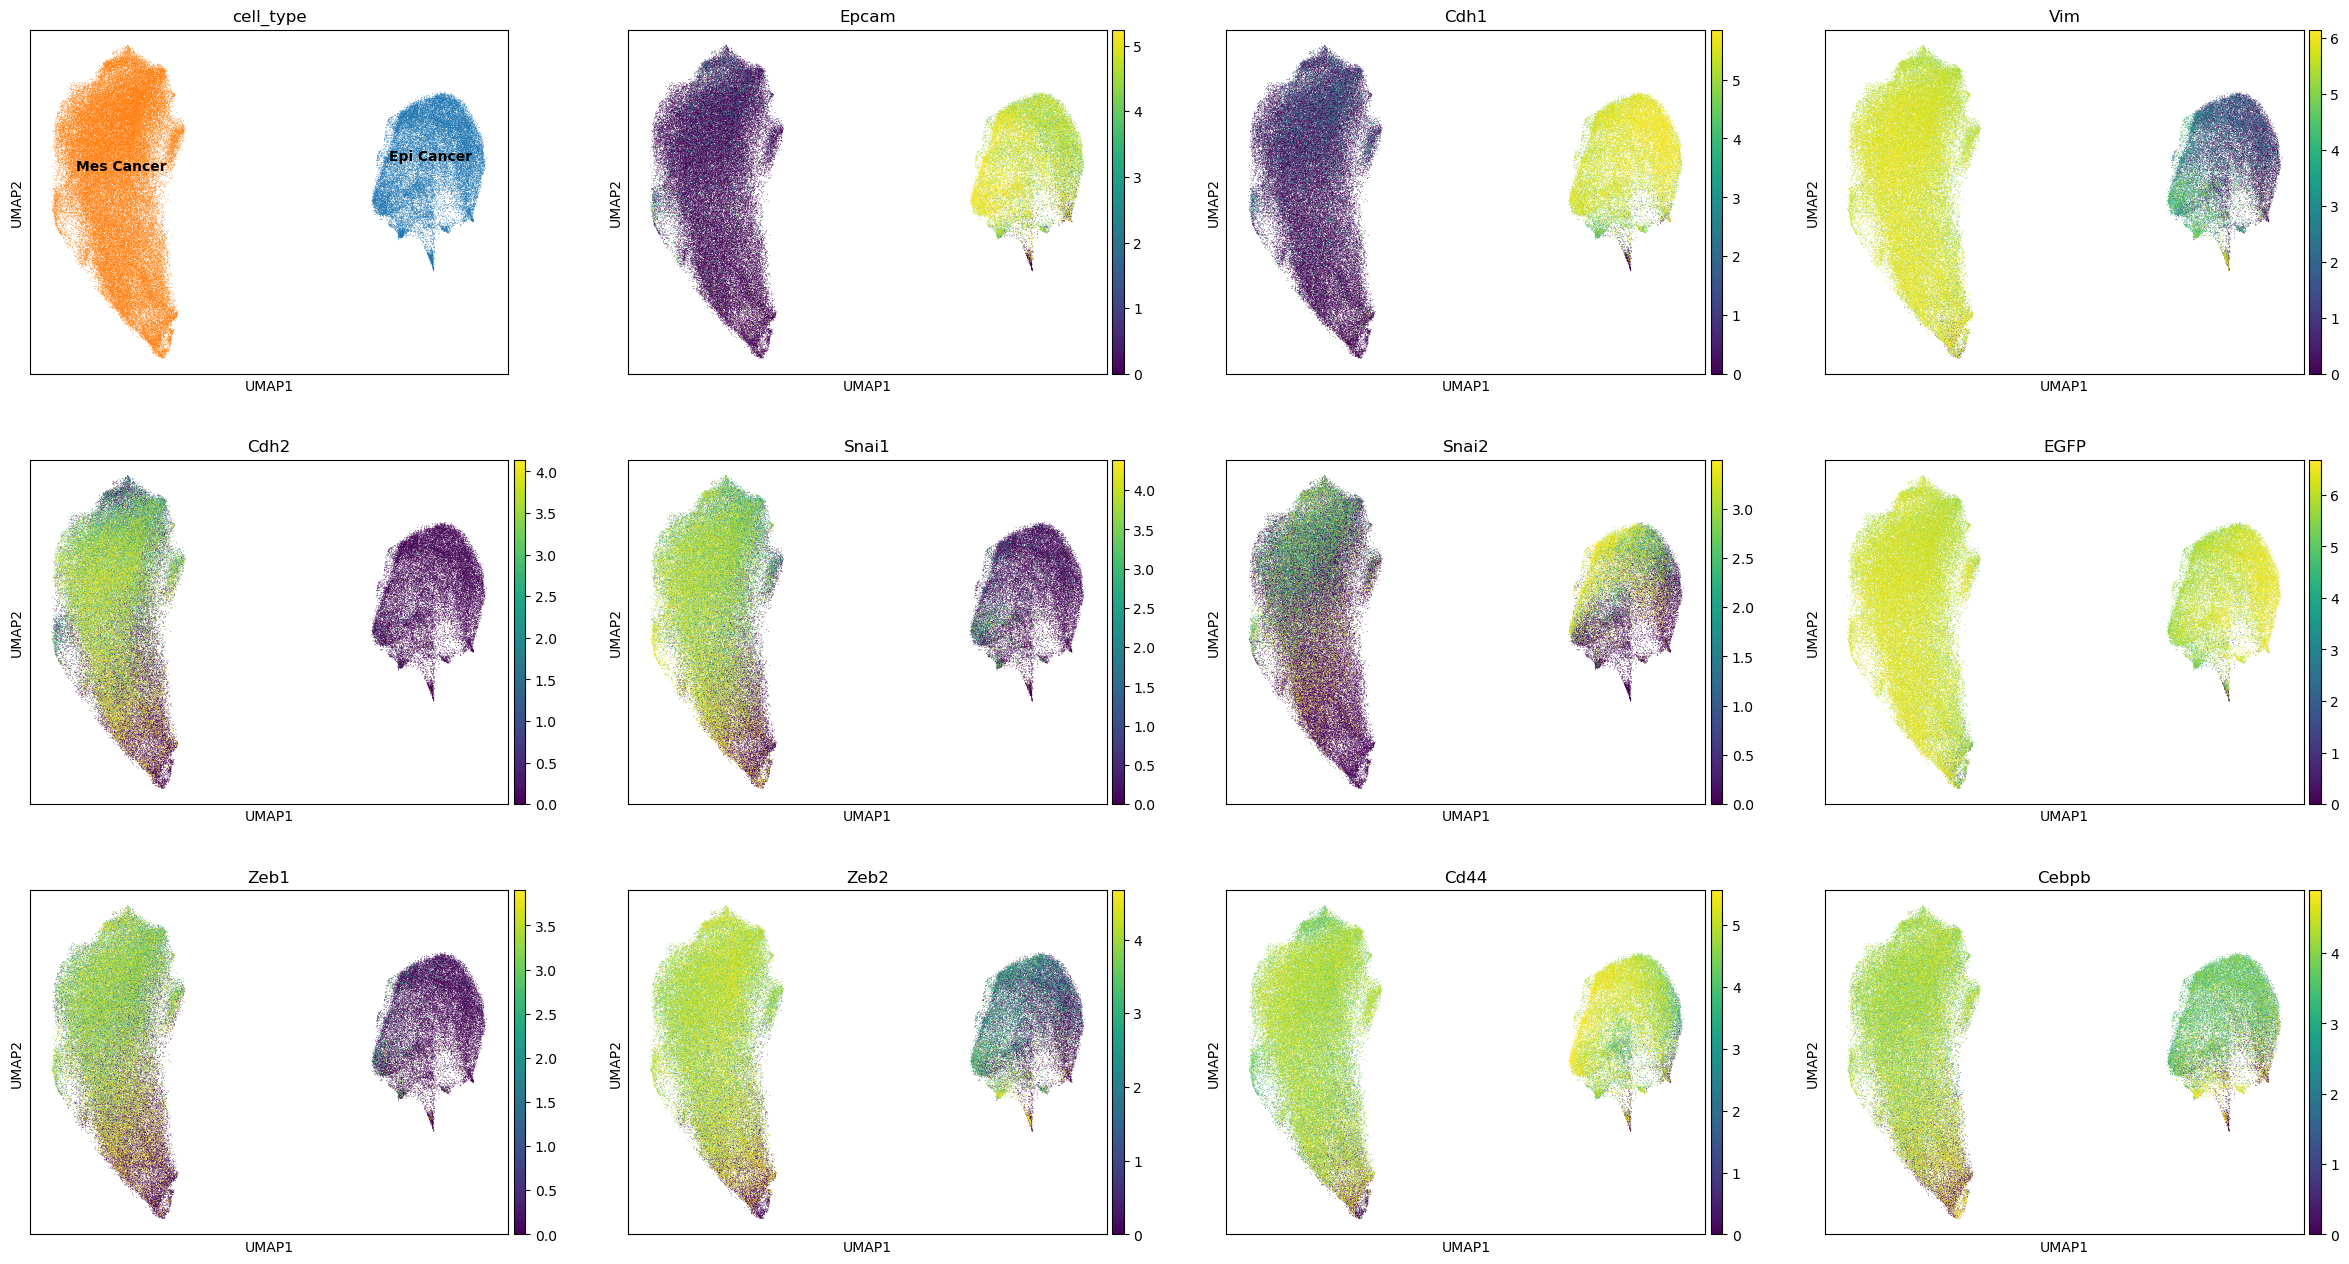

In [6]:
sc.pl.umap(tumor,color=['cell_type',
                'Epcam','Cdh1','Vim','Cdh2','Snai1','Snai2','EGFP','Zeb1','Zeb2','Cd44','Cebpb'],
           legend_loc='on data',
           vmin=0,vmax='p95',show=False) # Clearly 2 clusters: Epi, Mes
plt.savefig("../Plots/111026 Tumor Markers UMAP.png", bbox_inches="tight",dpi=600)

In [19]:
xen.obs.columns

Index(['cell_id', 'x', 'y', 'cell_area', 'samp', 'condition', 'region',
       'Tumor Core', 'Cell Type', 'n_genes_by_counts',
       'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts',
       'n_counts', 'leiden', 'cell_type', 'Tumor leiden', 'Tumor Core New',
       'Epithelial Core', 'Mesenchymal Core', 'Macrophage leiden',
       'Tumor Distance', 'Mesenchymal Distance', 'Tumor Fraction',
       'Mes Fraction', 'Macrophage Distance', 'RCTD_first_type',
       'RCTD_spot_class', 'RCTD_first_filtered', 'Macrophage RCTD',
       'RCTD_second_type', 'RCTD_corrected'],
      dtype='object')

In [10]:
xen.obs['cell_type'].value_counts()

cell_type
Mes Cancer                     76147
Stroma                         66247
Macrophages                    63980
B cells                        33354
Epi Cancer                     30003
T cells                        21673
Endothelial cells              13044
DCs                             6370
Plasma cells                    5736
Lymphatic endothelial cells     1620
Name: count, dtype: int64

In [7]:
macrophages = xen[xen.obs["cell_type"]=="Macrophages"].copy()

In [8]:
stroma_genes=['Acta2', 'Pdgfra', 'Pdgfrb', 'Fap', 'Pdpn', 'Dcn', 'Cxcl12', 'Tgfb1', 'Postn', 'Vim']
tumor_genes=['Epcam', 'Cdh1', 'Cdh2', 'Snai2', 'Plekhs1', 'Krt5', 'Col17a1', 'Twist2', 'Cd44', 'Zeb1', 'Zeb2', 'Twist1', 'S100a4', 'Snai1', 'Col6a2', 'EGFP', 'mCherry', 'Myc','Ki67','Top2a','Csf1']

In [9]:
# Analysis
keep_genes = ~macrophages.var_names.isin(stroma_genes + tumor_genes)
macrophages = macrophages[:,keep_genes]
macrophages.shape

(63980, 270)

In [10]:
# Run UMAP clustering 
# 5. Re-run Neighbors, UMAP, and Clustering
sc.pp.neighbors(macrophages, use_rep="X_pca_harmony")
sc.tl.umap(macrophages, min_dist=0.1)
sc.tl.leiden(macrophages, resolution=0.4)

In [ ]:
sc.pl.umap(macrophage_subset,color=['Macrophage leiden','RCTD_corrected',
                'Itgam','Adgre1','Nos2','Cd68', 'Cxcl10','Cxcl9','Ccr2','Mrc1','Arg1','H2-Ab1','Spp1','Cebpb'],
           legend_loc='on data',
           vmin=0,vmax='p95', show=False)
plt.savefig("../Plots/111026 Macrophage Markers UMAP.png", bbox_inches="tight",dpi=600)

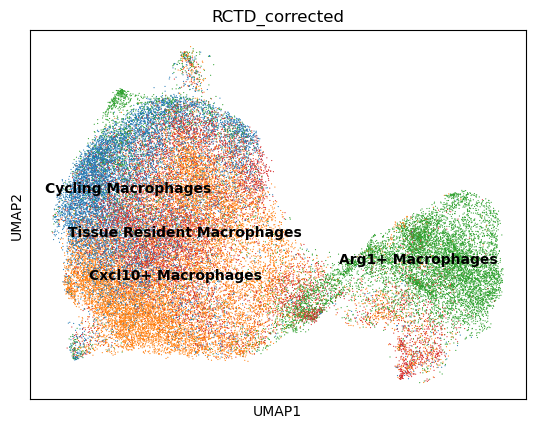

In [15]:
macrophage_subset = macrophages[macrophages.obs["RCTD_corrected"].isin(["Tissue Resident Macrophages", "Arg1+ Macrophages","Cycling Macrophages", "Cxcl10+ Macrophages"])].copy()
sc.pl.umap(macrophage_subset,color=['RCTD_corrected'],
           legend_loc='on data',
           vmin=0,vmax='p95', show=False)
plt.savefig("../Plots/110826 Macrophage leiden UMAP.png", bbox_inches="tight",dpi=600)

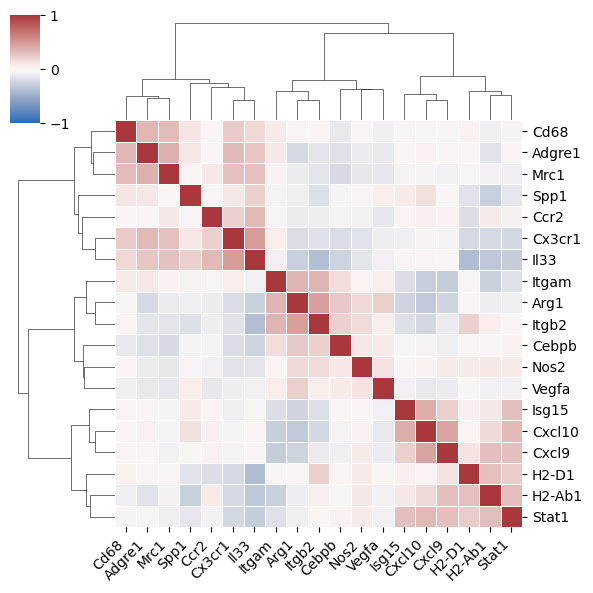

In [28]:
# Do hierchical clustering of macrophage markers
# 1. Define your macrophage markers
macrophage_markers = ['Itgam','Adgre1','Nos2','Cd68', 'Cxcl10','Cxcl9','Ccr2','Mrc1','Arg1','H2-Ab1','H2-D1','Cx3cr1','Isg15','Stat1','Spp1','Cebpb','Vegfa','Itgb2','Il33']
# Filter to ensure they exist in your dataset
markers_present = [g for g in macrophage_markers if g in macrophages.var_names]

# 2. Extract the expression data into a dense DataFrame
# Using adata.to_df() automatically pulls from adata.X (or use layer='normalized' if needed)
expr_df = macrophages[:, markers_present].to_df()

# 3. Calculate the gene-gene correlation matrix
# correlation over columns (genes)
gene_corr = expr_df.corr(method='spearman') # or 'spearman' for non-linear correlation

# 4. Generate the hierarchical clustered heatmap
g = sns.clustermap(
    gene_corr,
    cmap="vlag",              # Diverging colormap (blue for negative, red for positive correlation)
    vmin=-1, vmax=1,          # Fix the correlation scale boundaries
    metric="euclidean",       # Distance metric for clustering
    method="ward",            # Linkage method
    linewidths=.5,
    figsize=(6, 6)
)

# Rotate labels for readability
g.ax_heatmap.set_xticklabels(g.ax_heatmap.get_xticklabels(), rotation=45, horizontalalignment='right')
g.savefig("../Plots/111026 Macrophage Marker Hierarchical Clustering.png", bbox_inches="tight",dpi=600)

In [21]:
rename_dict = {
    "Intratumoral": "Epithelial",
    "Stroma": "Non-Epithelial"
}

# 1. Ensure the column is treated as a category if it isn't already
xen.obs['Epithelial Core'] = xen.obs['Epithelial Core'].astype(str)
xen.obs['Epithelial Core'] = xen.obs['Epithelial Core'].map(rename_dict).astype('category')

/tmp/ipykernel_3404995/3894383036.py:12: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/tmp/ipykernel_3404995/3894383036.py:12: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/tmp/ipykernel_3404995/3894383036.py:12: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/tmp/ipykernel_3404995/3894383036.py:12: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/tmp/ipykernel_3404995/3894383036.py:12: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


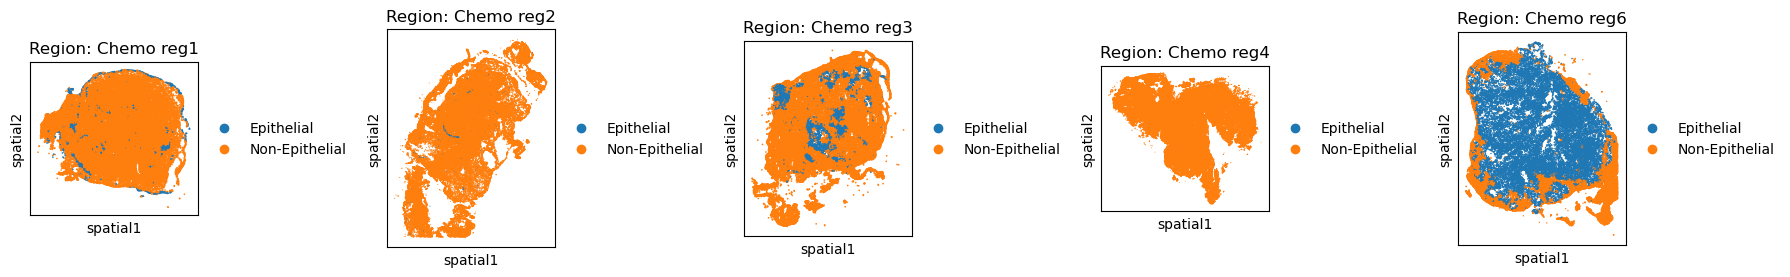

In [22]:
regs = xen.obs['region'].unique()
regs = ["Chemo reg1", "Chemo reg2", "Chemo reg3", "Chemo reg4", "Chemo reg6"]
# Create a 2x3 grid of subplots
fig, axes = plt.subplots(1, 5, figsize=(18, 5))
axes = axes.flatten()

for i, reg_id in enumerate(regs):
    # Subset data for just this region
    subset = xen[xen.obs["region"] == reg_id].copy()
    
    # Plot on its own dedicated subplot axis
    sc.pl.spatial(
        subset, 
        color="Epithelial Core", 
        spot_size=30, 
        img_key=None, 
        ax=axes[i], 
        show=False,
        title=f"Region: {reg_id}"
    )

plt.tight_layout()
plt.savefig("../Plots/110826 Tumor and Stromal Compartments.png", bbox_inches="tight",dpi=600)
plt.show()

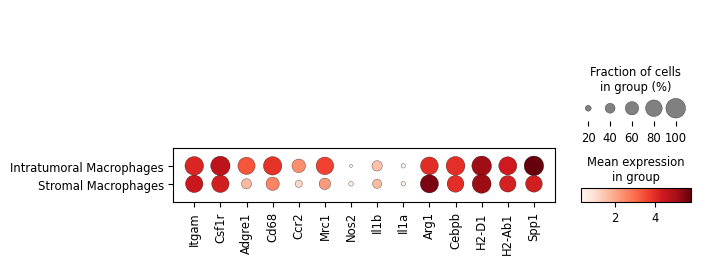

In [21]:
# Compare between Macrophages <50um away from tumor cells, and Macrophages >50um away from tumor cells
mac_marker_genes =['Itgam', 'Csf1r','Adgre1', 'Cd68', 'Ccr2', 'Mrc1', 'Nos2', 'Il1b', 'Il1a', 'Arg1','Cebpb','H2-D1','H2-Ab1','Spp1']
dp = sc.pl.dotplot(
    macrophages, 
    var_names= mac_marker_genes, 
    groupby='Macrophage leiden',        # Column name in adata.obs for cell types
    cmap='Reds',             # Color map for average expression
    expression_cutoff=0.0,    # Threshold for counting a cell as "expressing"
    colorbar_title='Mean expression\nin group',
    size_title='Fraction of cells\nin group (%)',
    return_fig = True)
dp.savefig('../Plots/110826 Macrophage_markers.pdf', bbox_inches='tight')

[  4.96769137  10.88042443  13.08019458  16.77690365  46.4848322
 823.63182624]


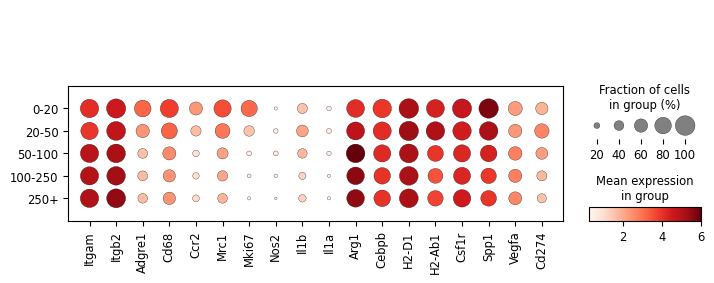

In [23]:
macrophages.obs["tumor_distance_bin2"] = pd.cut(
    macrophages.obs["Tumor Distance"],
    bins=[0,10,20,50,100,np.inf],
    labels=["0-10","10-20", "20-50", "50-100", "100-250", "250+"]
)
# Get the actual bins
bins = pd.qcut(
    macrophages.obs["Tumor Distance"],
    q=5,
    retbins=True
)
print(bins[1])
# Plot marker expression bubbleplot
mac_marker_genes =['Itgam','Itgb2','Adgre1', 'Cd68', 'Ccr2', 'Mrc1', 'Mki67',
                   'Nos2', 'Il1b', 'Il1a', 'Arg1','Cebpb','H2-D1','H2-Ab1','Csf1r','Spp1','Vegfa','Cd274']
dp = sc.pl.dotplot(
    macrophages, 
    var_names= mac_marker_genes, 
    groupby='tumor_distance_bin2',        # Column name in adata.obs for cell types
    cmap='Reds',             # Color map for average expression
    expression_cutoff=0.0,    # Threshold for counting a cell as "expressing"
    colorbar_title='Mean expression\nin group',
    size_title='Fraction of cells\nin group (%)',
    return_fig = True)
dp.savefig('../Plots/110826 Macrophage_markers_by_tumor_distance.pdf', bbox_inches='tight')

In [25]:
macrophages.obs["tumor_distance_bin"] = pd.cut(
    macrophages.obs["Tumor Distance"],
    bins=[0,50,np.inf],
    labels=["0-50", "50+"]
)

In [32]:
sc.tl.rank_genes_groups(
    macrophages,
    groupby="tumor_distance_bin",
    groups=["50+"],
    reference="0-50",
    method="wilcoxon"   # or "t-test", "logreg"
)
de = sc.get.rank_genes_groups_df(macrophages, group=["50+"])
de = de[de["logfoldchanges"]>0.5]
de.head(20)

,names,scores,logfoldchanges,pvals,pvals_adj
0,Itgb2,100.732277,1.076094,0.000000e+00,0.000000e+00
1,Lyz2,97.981369,1.195451,0.000000e+00,0.000000e+00
2,Arg1,96.251266,2.080204,0.000000e+00,0.000000e+00
3,Itgam,95.659309,1.314627,0.000000e+00,0.000000e+00
4,Fn1,91.936768,0.886314,0.000000e+00,0.000000e+00
8,Vegfa,35.033890,0.710976,6.860364e-269,2.646140e-268
11,Sell,29.788820,1.978808,5.452839e-195,1.817613e-194
12,C1s1,29.721155,2.028683,4.092720e-194,1.347603e-193
13,Clu,28.575552,0.701825,1.352703e-179,4.347973e-179
14,Jchain,25.241371,1.845701,1.408663e-140,4.225990e-140


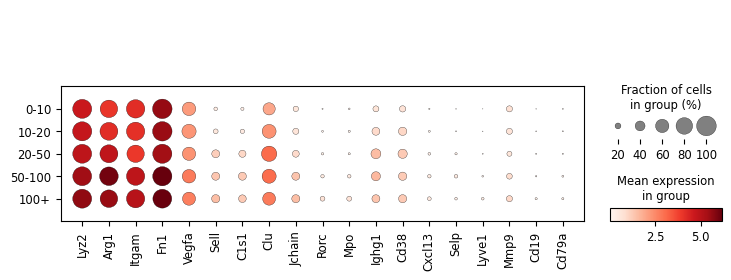

In [33]:
macrophages.obs["tumor_distance_bin2"] = pd.cut(
    macrophages.obs["Tumor Distance"],
    bins=[0,10,20,50,100,np.inf],
    labels=["0-10","10-20", "20-50", "50-100", "100+"]
)
top20= de["names"][1:20]
dp = sc.pl.dotplot(
    macrophages, 
    var_names= top20, 
    groupby='tumor_distance_bin2',        # Column name in adata.obs for cell types
    cmap='Reds',             # Color map for average expression
    expression_cutoff=0.0,    # Threshold for counting a cell as "expressing"
    colorbar_title='Mean expression\nin group',
    size_title='Fraction of cells\nin group (%)',
    return_fig = True)
dp.savefig('../Plots/110826 Stromal Mac enriched genes.pdf', bbox_inches='tight')

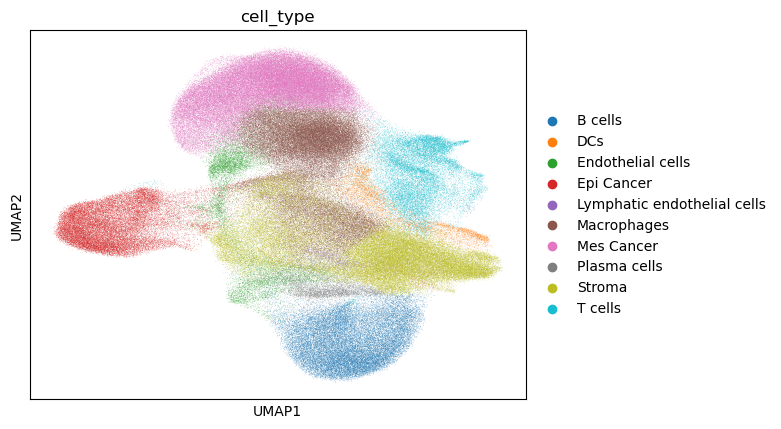

In [36]:
# Calculate odds ratio 
sc.pl.umap(xen,color="cell_type",show=False)
plt.savefig('../Plots/110826 Cell Types UMAP.pdf', bbox_inches='tight')

In [37]:
# Calculate odds ratio % expressing 
macrophages.X = macrophages.layers['counts'].copy()

In [38]:
# For each gene, calculate odds ratio of % expressing >2 counts between 0-50um and >50um 
odds_ratio_intratumor = np.zeros(len(macrophages.var_names))
for i, gene in enumerate(macrophages.var_names):
    # Calculate fraction > 2 counts in 0-50um and >50um 
    

270

In [2]:
xen.X = xen.layers['lognorm'].copy()

NameError: name 'xen' is not defined

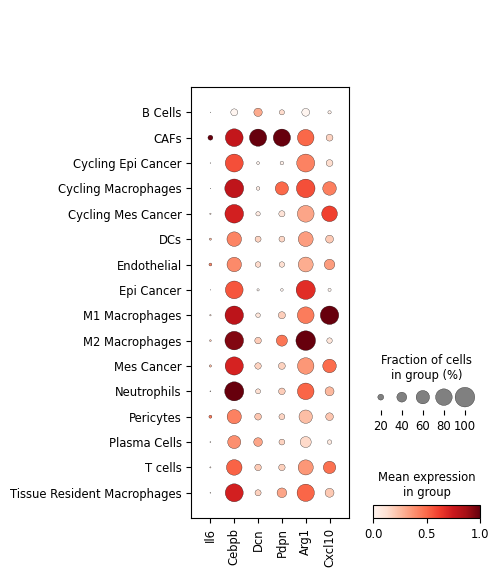

In [3]:
# Set M1 Macrophages as CXCL10+ 
dp = sc.pl.dotplot(
    xen, 
    var_names= ['Il6','Cebpb','Dcn','Pdpn','Arg1','Cxcl10'], 
    groupby='RCTD_corrected',        # Column name in adata.obs for cell types
    cmap='Reds',             # Color map for average expression
    expression_cutoff=0.0,    # Threshold for counting a cell as "expressing"
    colorbar_title='Mean expression\nin group',
    size_title='Fraction of cells\nin group (%)',
    standard_scale='var',
    return_fig = True)
dp.savefig('../Plots/RCTD_cell_marker_genes.pdf', bbox_inches='tight')